# Análisis exploratorio de datos
### Predicción de intención de compra en tiendas online

**Objetivo:** Antes de entrenar modelos, vamos a conocer bien los datos con los que vamos a trabajar.
La idea es entender que información tenemos, comprobar si hay problemas y buscar patrones
que puedan estar relacionados con que un usuario compre.

En este notebook analizaremos:

- Cómo están organizados los datos y si tienen errores o valores repetidos.
- Cuántas sesiones terminan en compra y cuántas no.
- Cómo se comportan las las variables numéricas.
- Qué diferencias hay entre sesiones con y sin compra.
- Qué relaciones  hay entre características.
- Qué importancia y limitaciones tiene PageValues.

### 1.1. Importaciones

In [83]:
from pathlib import Path
from sklearn.model_selection import train_test_split
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# para localizar la raid del proyecto
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))


# Configuración visual que damos al notebook
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

### 1.2. Carga de datos

In [84]:
RANDOM_STATE = 42

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

RUTA_CSV = RAIZ / "data" / "raw" / "online_shoppers_intention.csv"

datos = pd.read_csv(RUTA_CSV)

# Eliminación de duplicados y división estratificada

datos_limpios = datos.drop_duplicates().reset_index(drop=True)

X = datos_limpios.drop(columns="Revenue")
y = datos_limpios["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Dataset utilizado en los análisis del entrenamiento
df = X_train.copy()
df["Revenue"] = y_train

print(f"Sesiones originales: {len(datos):,}")
print(f"Duplicados eliminados: {len(datos) - len(datos_limpios)}")
print(f"Entrenamiento: {len(X_train):,}")
print(f"Prueba: {len(X_test):,}")

# Vista inicial del dataset original
display(datos.head())

Sesiones originales: 12,330
Duplicados eliminados: 125
Entrenamiento: 9,764
Prueba: 2,441


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Aquí podemos ver las primeras filas del dataset para hacernos una idea de cómo están organizados los datos y qué información
tiene cada columna.

## 2. Calidad de los datos

Antes de estudiar relaciones entre variables o entrenar clasificadores, vamos a verificar la calidad del conjunto de datos.

En esta sección hemos examinado su estructura, identificado las variables numéricas y categóricas, cuantificado los valores 
ausentes y los registros duplicados y comprobado que los datos fueran coherentes.

El análisis estructural lo hemos realizado sobre el CSV original. Para poder estudiar relaciones con la variable objetivo 
y desarrollar los modelos hemos utilziado exclusivamente el conjunto de entrenamiento.

### 2.1. Variables y tipos de datos

El dataset contiene 17 características predictoras y una variable
objetivo, `Revenue`, la cual indica si una sesión terminó en compra.

Hemos diferenciado entre variables numéricas y categóricas según su
significado, no únicamente según el tipo de dato almacenado. Por
ejemplo, `Browser` utiliza códigos enteros, pero representa categorías
de navegadores y no una magnitud cuantitativa.

In [85]:
variables_numericas = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

variables_categoricas = [
    "Month", "OperatingSystems", "Browser",
    "Region", "TrafficType", "VisitorType", "Weekend"
]

assert set(variables_numericas + variables_categoricas) == (
    set(datos.columns) - {"Revenue"}
)

inventario = pd.DataFrame({
    "Variable": datos.columns,
    "Tipo de dato": [str(datos[c].dtype) for c in datos.columns],
    "Naturaleza": [
        "Objetivo" if c == "Revenue"
        else "Numérica" if c in variables_numericas
        else "Categórica"
        for c in datos.columns
    ],
    "Valores distintos": [datos[c].nunique() for c in datos.columns],
    "Valores ausentes": [datos[c].isna().sum() for c in datos.columns],
})

display(inventario)

print(f"Variables numéricas: {len(variables_numericas)}")
print(f"Variables categóricas: {len(variables_categoricas)}")
print("Variable objetivo: Revenue")

,Variable,Tipo de dato,Naturaleza,Valores distintos,Valores ausentes
0,Administrative,int64,Numérica,27,0
1,Administrative_Duration,float64,Numérica,3335,0
2,Informational,int64,Numérica,17,0
3,Informational_Duration,float64,Numérica,1258,0
4,ProductRelated,int64,Numérica,311,0
5,ProductRelated_Duration,float64,Numérica,9551,0
6,BounceRates,float64,Numérica,1872,0
7,ExitRates,float64,Numérica,4777,0
8,PageValues,float64,Numérica,2704,0
9,SpecialDay,float64,Numérica,6,0


Variables numéricas: 10
Variables categóricas: 7
Variable objetivo: Revenue


**Interpretación**

Al revisar las 18 columnas hemos visto que no hay ningún valor ausente. Esto es una buena noticia porque no tendremos que rellenar los datos que falten ni eliminar filas por este motivo.

### 2.2. Análisis de valores ausentes

Que haya valores ausentes puede afectar a la preparación de los datos y al rendimiento de los algoritmos.

Hemos comprobado tanto el número absoluto de valores ausentes como su porcentaje por variable  con el objetivo de determinar si es
necesario aplicar alguna estrategia de imputación o eliminación.

In [86]:
nulos = datos.isna().sum().sort_values(ascending=False)
porcentajes_nulos = nulos / len(datos) * 100

tabla_nulos = pd.DataFrame({
    "Valores ausentes": nulos,
    "Porcentaje (%)": porcentajes_nulos.round(3)
})

display(tabla_nulos)

total_nulos = int(nulos.sum())
columnas_afectadas = int((nulos > 0).sum())

print(f"Total de valores ausentes: {total_nulos}")
print(f"Columnas afectadas: {columnas_afectadas}")

,Valores ausentes,Porcentaje (%)
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Total de valores ausentes: 0
Columnas afectadas: 0


### 2.3. Detección y tratamiento de duplicados

Los registros duplicados pueden influir en el entrenamiento y en la evaluación de los modelos, especialmente si dos filas idénticas aparecen
simultáneamente en los conjuntos de entrenamiento y prueba.

Hemos comprobado cuántas filas están repetidas exactamente y hemos cuantificado su peso respecto al total. También hemos analizado la decisión de
eliminarlas, teniendo en cuenta que dos sesiones reales podrían compartir todas sus características.

,Indicador,Cantidad
0,Sesiones originales,12330
1,Filas duplicadas,125
2,Sesiones tras eliminar duplicados,12205


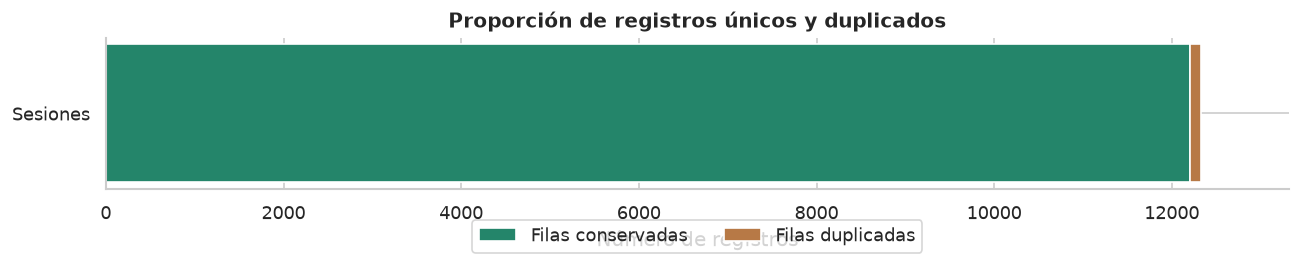

Duplicados: 125 (1.01%)
Sesiones conservadas: 12,205


In [87]:
n_original = len(datos)
n_duplicados = int(datos.duplicated().sum())
n_unicos = len(datos.drop_duplicates())

resumen_duplicados = pd.DataFrame({
    "Indicador": [
        "Sesiones originales",
        "Filas duplicadas",
        "Sesiones tras eliminar duplicados"
    ],
    "Cantidad": [n_original, n_duplicados, n_unicos]
})

display(resumen_duplicados)

fig, ax = plt.subplots(figsize=(11, 2.8))

ax.barh(
    ["Sesiones"],
    [n_unicos],
    color="#24856A",
    label="Filas conservadas"
)

ax.barh(
    ["Sesiones"],
    [n_duplicados],
    left=[n_unicos],
    color="#B77946",
    label="Filas duplicadas"
)

ax.set_xlim(0, n_original * 1.08)
ax.set_xlabel("Número de registros")
ax.set_title("Proporción de registros únicos y duplicados")

ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.48), ncol=2)
plt.tight_layout()
plt.show()

print(f"Duplicados: {n_duplicados:,} ({n_duplicados/n_original:.2%})")
print(f"Sesiones conservadas: {n_unicos:,}")

**Interpretación y decisiones**

Hemos identificado 125 registros duplicados de las 12.330 sesiones originales, lo que representa aproximadamente el **1,01 % del dataset**.

Hemos decidido eliminar estos duplicados antes de dividir los datos en entrenamiento y prueba. Así evitamos que
una misma fila aparezca en ambos conjuntos y pueda hacer que los resultados del modelo sean demasiado optimistas.

Aun así que dos filas tengan exactamente los mismos valores no significa que 100% correspondan a una misma visita real. Por eso hemos considerado que eliminar estos registros es una decisión metodológica que hemos tomado y que dejamos documentada.

### 2.4. Coherencia y validez de los registros

Aunque el dataset no tiene valores ausentes hemos tenido que comprobar si existen valores que sean incompatibles con el significado de las variables.

Hemos revisado los valores negativos, los infinitos, los recuentos no enteros y las tasas fuera de rango. También hemos examinado la relación entre el
número de páginas visitadas y el tiempo registrado en ellas.

In [88]:
columnas_recuento = [
    "Administrative", "Informational", "ProductRelated"
]

columnas_tasas = [
    "BounceRates", "ExitRates", "SpecialDay"
]

columnas_enteras = columnas_recuento + [
    "OperatingSystems", "Browser", "Region", "TrafficType"
]

auditoria = {
    "Valores numéricos negativos": int(
        (datos[variables_numericas] < 0).sum().sum()
    ),
    "Valores infinitos": int(
        np.isinf(datos.select_dtypes(include="number").to_numpy()).sum()
    ),
    "Recuentos o códigos no enteros": int(
        (datos[columnas_enteras] % 1 != 0).sum().sum()
    ),
    "Tasas fuera de [0, 1]": int(
        ((datos[columnas_tasas] < 0) |
         (datos[columnas_tasas] > 1)).sum().sum()
    ),
}

tabla_auditoria = pd.DataFrame(
    auditoria.items(),
    columns=["Comprobación", "Incidencias"]
)

display(tabla_auditoria)

# Comprobar relaciones entre visitas y duraciones
pares = [
    ("Administrative", "Administrative_Duration"),
    ("Informational", "Informational_Duration"),
    ("ProductRelated", "ProductRelated_Duration"),
]

coherencia = []

for paginas, duracion in pares:
    coherencia.append({
        "Tipo de página": paginas,
        "0 páginas y duración > 0": int(
            ((datos[paginas] == 0) & (datos[duracion] > 0)).sum()
        ),
        "Páginas > 0 y duración = 0": int(
            ((datos[paginas] > 0) & (datos[duracion] == 0)).sum()
        ),
    })

display(pd.DataFrame(coherencia))

,Comprobación,Incidencias
0,Valores numéricos negativos,0
1,Valores infinitos,0
2,Recuentos o códigos no enteros,0
3,"Tasas fuera de [0, 1]",0


,Tipo de página,0 páginas y duración > 0,Páginas > 0 y duración = 0
0,Administrative,0,135
1,Informational,0,226
2,ProductRelated,0,717


**Interpretación y conclusiones**

No hemos visto valores negativos, infinitos, códigos no enteros ni tasas fuera del intervalo establecido. Por tanto, creemos que no hay errores muy evidentes.

Tampoco existen sesiones con una duración positiva registrada para páginas cuyo recuento de visitas sea cero.

Sin embargo, sí que hay sesiones que registran páginas visitadas con una duración igual a cero:
- 135 casos para páginas administrativa.
- 226 para informativas.
- 717 para páginas de productos.

Esto no significa que los datos estén mal. Puede que el sistema de medición no haya registrado el tiempo y por eso de momento conservamos estas filas y tendremos en cuenta esta particulariedad cuando interpretemos los resultados.

### 2.5. Presencia de valores cero

Algunas características de navegación pueden tener valor cero y tener sentido. Por ejemplo, una sesión puede no incluir visitas a páginas informativas, o presentar un PageValues igual a cero.

Hemos analizado la proporción de ceros en cada característica numérica para identificar variables con distribuciones muy concentradas y
determinar qué visualizaciones serán más adecuadas posteriormente.

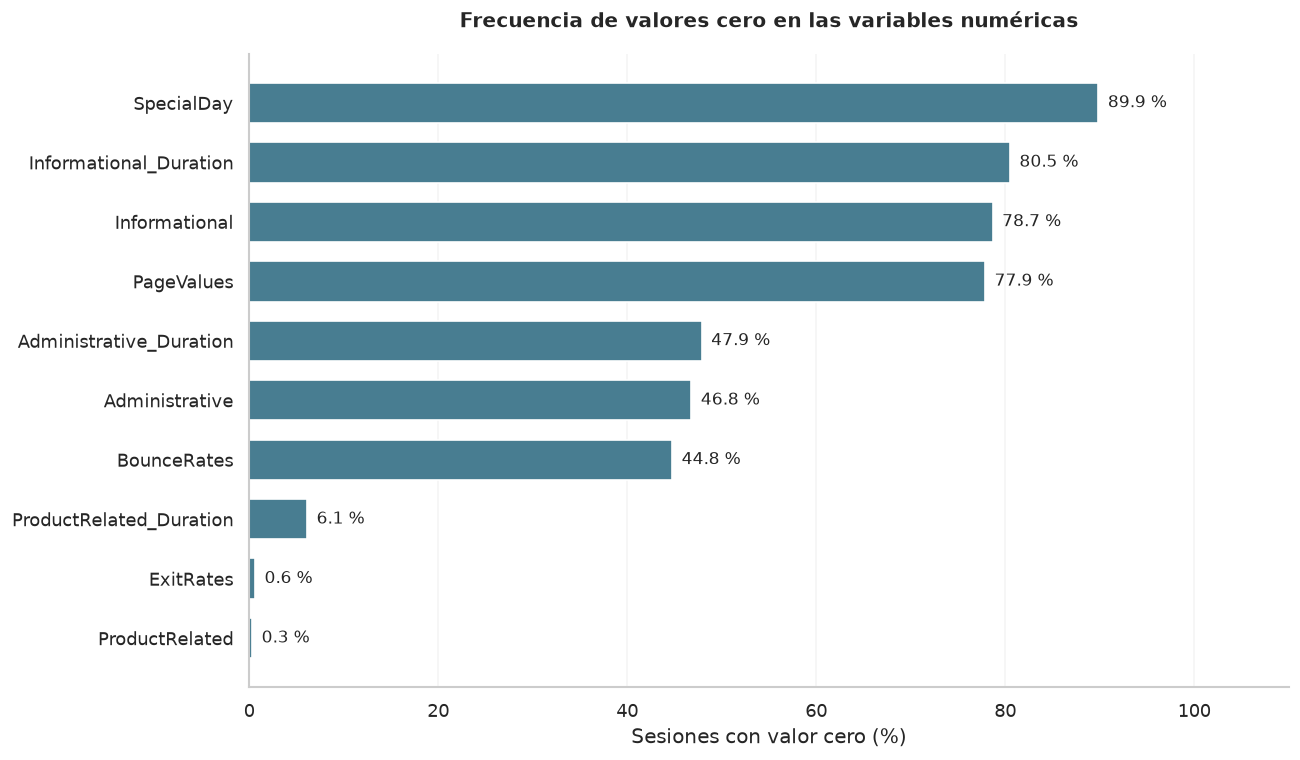

In [89]:
porcentaje_ceros = (
    datos[variables_numericas]
    .eq(0)
    .mean()
    .mul(100)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 6.5))

barras = ax.barh(
    porcentaje_ceros.index,
    porcentaje_ceros.values,
    color="#487D91",
    height=0.68
)

for barra, porcentaje in zip(barras, porcentaje_ceros.values):
    ax.text(
        porcentaje + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{porcentaje:.1f} %",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, 110)
ax.set_xlabel("Sesiones con valor cero (%)")
ax.set_title(
    "Frecuencia de valores cero en las variables numéricas",
    pad=16
)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

No todas las variables tienen la misma cantidad de ceros. Algunas ideas que hemos podido sacar son
- Proximidad a fecha especial: `SpecialDay` destaca con un 89,9 % de valores 0. La mayoría de las sesiones no presenta proximidad a una fecha especial según esta medida.
- Escasa navegación por páginas informativas: `Informational` y `Informational_Duration` registran valores cero en el 78,7 % y el 80,5 % de las sesiones, respectivamente. 
- Las páginas de productos tienen una presencia mucho mayor: `ProductRelated` apenas presenta un 0,3 % de ceros.
- `PageValues` tiene un valor cero en el 77,9 % de las sesiones. Más adelante hemos analizado su distribución y su relación con la compra para determinar qué información puede aportar.

Estas diferencias nos muestran que varias características concentran gran parte de sus observaciones en cero, lo que puede dar lugar a distribuciones muy asimétricas. Aun así debemos recordar que estos ceros no representan datos ausentes, sino valores registrados en el dataset.

## 3. Análisis de la variable objetivo

La variable `Revenue` nos indica si una sesión terminó en compra (`True`) o no (`False`). Se trata de un problema de clasificación binaria.

Antes de entrenar los modelos, hemos analizado la distribución de ambas clases para ver si existe un desequilibrio que debamos tener
en cuenta durante el entrenamiento y la evaluación.

### 3.1. Distribución de las clases

Hemos representado el número y la proporción de sesiones de entrenamiento que terminan en compra y no compra.

El análisis lo hemos hecho sobre el conjunto de entrenamiento, tras eliminar los duplicados del dataset original. El conjunto de prueba
lo mantenemos reservado para la evaluación final.

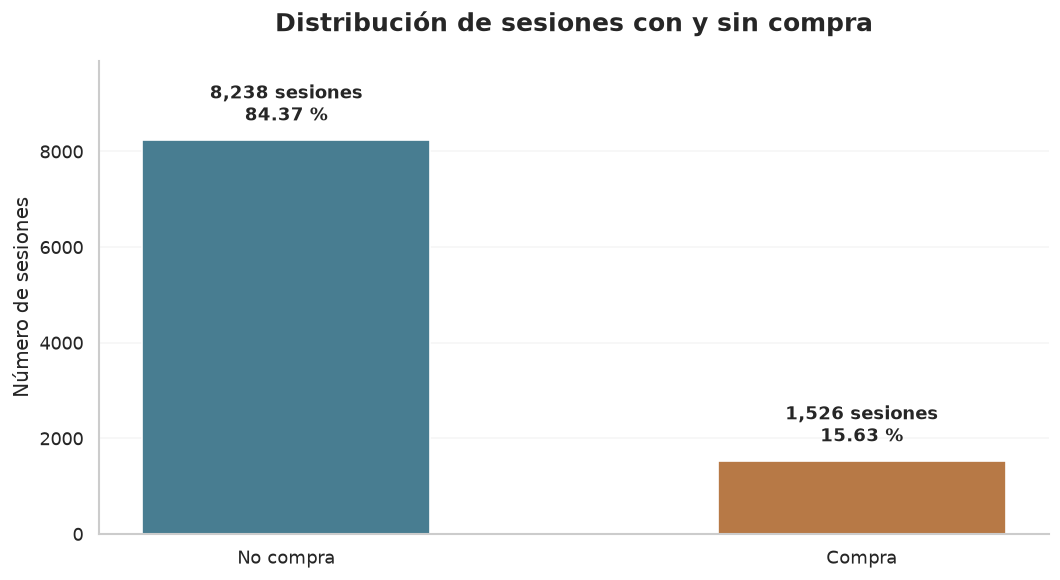

In [90]:
conteos = df["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    ["No compra", "Compra"],
    conteos.values,
    color=["#487D91", "#B77946"],
    width=0.5
)

for barra, valor in zip(barras, conteos.values):
    porcentaje = valor / len(df) * 100

    ax.annotate(
        f"{valor:,} sesiones\n{porcentaje:.2f} %",
        (
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        ha="center",
        va="bottom",
        xytext=(0, 8),
        textcoords="offset points",
        fontweight="bold",
        fontsize=11
    )

ax.set_title(
    "Distribución de sesiones con y sin compra",
    fontsize=15,
    pad=18
)
ax.set_ylabel("Número de sesiones")
ax.set_ylim(0, conteos.max() * 1.2)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.18)

plt.tight_layout()
plt.show()

**Interpretación**

Podemos ver que la distribución de `Revenue` presenta mcuho desequilibrio. De las 9.764 sesiones de entrenamiento:
- 8.238 (84,37 %) no terminan en compra
- 1.526 (15,63 %) sí que terminan en compra

Esto supone que hay aproximadamente 5,4 sesiones sin compra por cada sesión con compra. Por tanto, la clase mayoritaria es "No compra".

Este desequilibrio lo vamos a tener en cuenta cuando comparemos los modelos, ya que una accuracy elevada no implica necesariamente una buena capacidad para identificar compradores. Por ello prestaremos especial atención a métricas como Precision, Recall, F1 y Average Precision, además de estudiar técnicas de rebalanceo.

### 3.2. Modelo Dummy de referencia: predicción de la clase mayoritaria

Para ilustrar las consecuencias del desequilibrio hemos considerado una estrategia trivial que clasifica todas las sesiones como "No compra", independientemente de sus características.

Hemos calculado sus métricas sobre las etiquetas del entrenamiento. Este ejercicio nos permitirá comprobar por qué no basta con utilizar la accuracy para evaluar nuestros futuros modelos.

In [91]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predicciones_base = np.zeros(len(y_train), dtype=bool)

metricas_base = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision (compra)",
        "Recall (compra)",
        "F1 (compra)"
    ],
    "Valor (%)": [
        accuracy_score(y_train, predicciones_base) * 100,
        balanced_accuracy_score(y_train, predicciones_base) * 100,
        precision_score(
            y_train, predicciones_base, zero_division=0
        ) * 100,
        recall_score(y_train, predicciones_base) * 100,
        f1_score(y_train, predicciones_base) * 100
    ]
})

display(
    metricas_base.style.format({"Valor (%)": "{:.2f}"})
)

,Métrica,Valor (%)
0,Accuracy,84.37
1,Balanced Accuracy,50.00
2,Precision (compra),0.00
3,Recall (compra),0.00
4,F1 (compra),0.00


**Interpretación**

El clasificador que predice siempre "No compra" consigue una accuracy del 84,37 %. Sin embargo, este resultado puede llevarnos a engaño, ya que no es capaz de identificar ninguna de las sesiones en las que sí se produce una compra.

Esto se refleja en que tanto el recall como el F1 de la clase positiva son iguales a cero. Además la balanced accuracy se queda en un 50%, lo que nos demuestra que el modelo no está aprendiendo a distinguir correctamente entre las dos clases.

Con este experimento podemos ver que cuando los datos están desequilibrados tener una accuracy alta no significa necesariamente que el modelo sea bueno.

Por ello no utilizaremos la accuracy como único criterio para poder comparar los modelos. Daremos más importancia a Average Precision que nos permitirá ver cómo de bien ordena el modelo las sesiones según su probabilidad de compra. También tendremos en cuenta otrás métricas como Precision, Recall y F1 para tener una visión más completa de los resultados.

### 3.3. Implicaciones para el modelado

El análisis de `Revenue` nos ha revelado dos aspectos que condicionarán los experimentos posteriores:

- **Evaluación:** hemos utilizado métricas adecuadas para clases desequilibradas, evitando seleccionar modelos únicamente por accuracy.
- **Tratamiento del desequilibrio:** hemos comparado el rendimiento de los modelos sin rebalanceo y después estudiaremos si
  hay técnicas específicas para permitir mejorar la identificación de compradores.

La separación entre entrenamiento y prueba la hemos hecho de forma estratificada, manteniendo proporciones similares de ambas clases. La optimización de modelos la hemos realizado mediante validación cruzada sobre entrenamiento, reservando el conjunto de prueba para la evaluación final.

## 4. Análisis univariante de las variables numéricas

En esta sección hemos estudiado individualmente las diez características numéricas del conjunto de entrenamiento.

Hemos analizado sus estadísticos descriptivos, distribuciones y valores extremos para comprender mejor el comportamiento de las sesiones.

En todo momento hemos utilizado unicamente el conjunto de entrenamiento.

### 4.1. Estadísticos descriptivos

Hemos calculado la media, mediana, desviación típica, cuartiles y percentiles superiores de las características numéricas.

La comparación entre media y mediana nos permite identificar posibles asimetrías, mientras que los percentiles 95 y 99 nos ayudan a estudiar la dispersión y los valores elevados sin depender únicamente del máximo.

In [92]:
estadisticos = df[variables_numericas].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T

estadisticos = estadisticos.rename(columns={
    "count": "N",
    "mean": "Media",
    "std": "Desv. típica",
    "min": "Mínimo",
    "25%": "P25",
    "50%": "Mediana",
    "75%": "P75",
    "95%": "P95",
    "99%": "P99",
    "max": "Máximo"
})

estadisticos = estadisticos.drop(columns=["N"])
estadisticos["Asimetría"] = df[variables_numericas].skew()

display(
    estadisticos.style
    .format("{:,.2f}")
    .background_gradient(
        subset=["Asimetría"],
        cmap="Blues"
    )
    .set_caption("Resumen estadístico de las variables numéricas")
)

,Media,Desv. típica,Mínimo,P25,Mediana,P75,P95,P99,Máximo,Asimetría
Administrative,2.34,3.35,0.00,0.00,1.00,4.00,9.00,14.00,27.00,1.99
Administrative_Duration,82.22,179.50,0.00,0.00,9.00,94.72,353.67,845.53,"3,398.75",5.68
Informational,0.51,1.28,0.00,0.00,0.00,0.00,3.00,6.00,24.00,4.10
Informational_Duration,34.95,143.83,0.00,0.00,0.00,0.00,193.21,746.85,"2,549.38",7.54
ProductRelated,32.10,44.82,0.00,8.00,18.00,39.00,109.85,221.00,705.00,4.39
ProductRelated_Duration,"1,207.26","1,926.39",0.00,193.47,617.00,"1,483.65","4,306.28","8,690.32","63,973.52",7.87
BounceRates,0.02,0.05,0.00,0.00,0.00,0.02,0.15,0.20,0.20,3.17
ExitRates,0.04,0.05,0.00,0.01,0.03,0.05,0.17,0.20,0.20,2.24
PageValues,5.95,18.86,0.00,0.00,0.00,0.00,38.11,86.66,361.76,6.55
SpecialDay,0.06,0.20,0.00,0.00,0.00,0.00,0.60,1.00,1.00,3.27


**Interpretación**

Todas las variables numéricas presentan **asimetría positiva**, es decir que la mayoría de los valores se concentran en niveles relativamente bajos, mientras que unos pocos alcanzan valores mucho más altos. Esto se aprecia especialmente en `ProductRelated_Duration` (7,87), `Informational_Duration` (7,54) y `PageValues` (6,55).

También hemos encontrado diferencias en la navegación según el tipo de página. Por ejemplo `ProductRelated` tiene una mediana de 18 páginas visitadas por sesión,`Administrative` tiene 1 e `Informational`tiene 0. Además, las duraciones también tienen bastante diferencia, en `ProductRelated_Duration` la media es de 1.207 segundos, casi el doble que la mediana (617 segundos) y el máximo supera los 63.000 segundos.

Por otra parte, `PageValues` tiene una mediana de 0 y una media de 5,95, lo que nos demuestra la concentración de valores bajos que ya habíamos observado. Su percentil 99 llega a 86,66 y el máximo llega a 361,76.

Estos resultados nos muestran distribuciones muy asimétricas, con grandes diferencias entre los valores habituales y los más elevados. Por ello hemos estudiado sus distribuciones gráficamente y examinar los valores extremos antes de decidir si necesitan algún tratamiento.

### 4.2. Distribuciones de navegación

Hemos analizado las tres categorías de páginas visitadas y sus respectivas duraciones: administrativas, informativas y relacionadas con productos.

Para facilitar la visualización hemos utilizado la transformación log(1 + x), que es adecuada para representar variables no negativas con
muchas observaciones pequeñas y una cola de valores elevados.

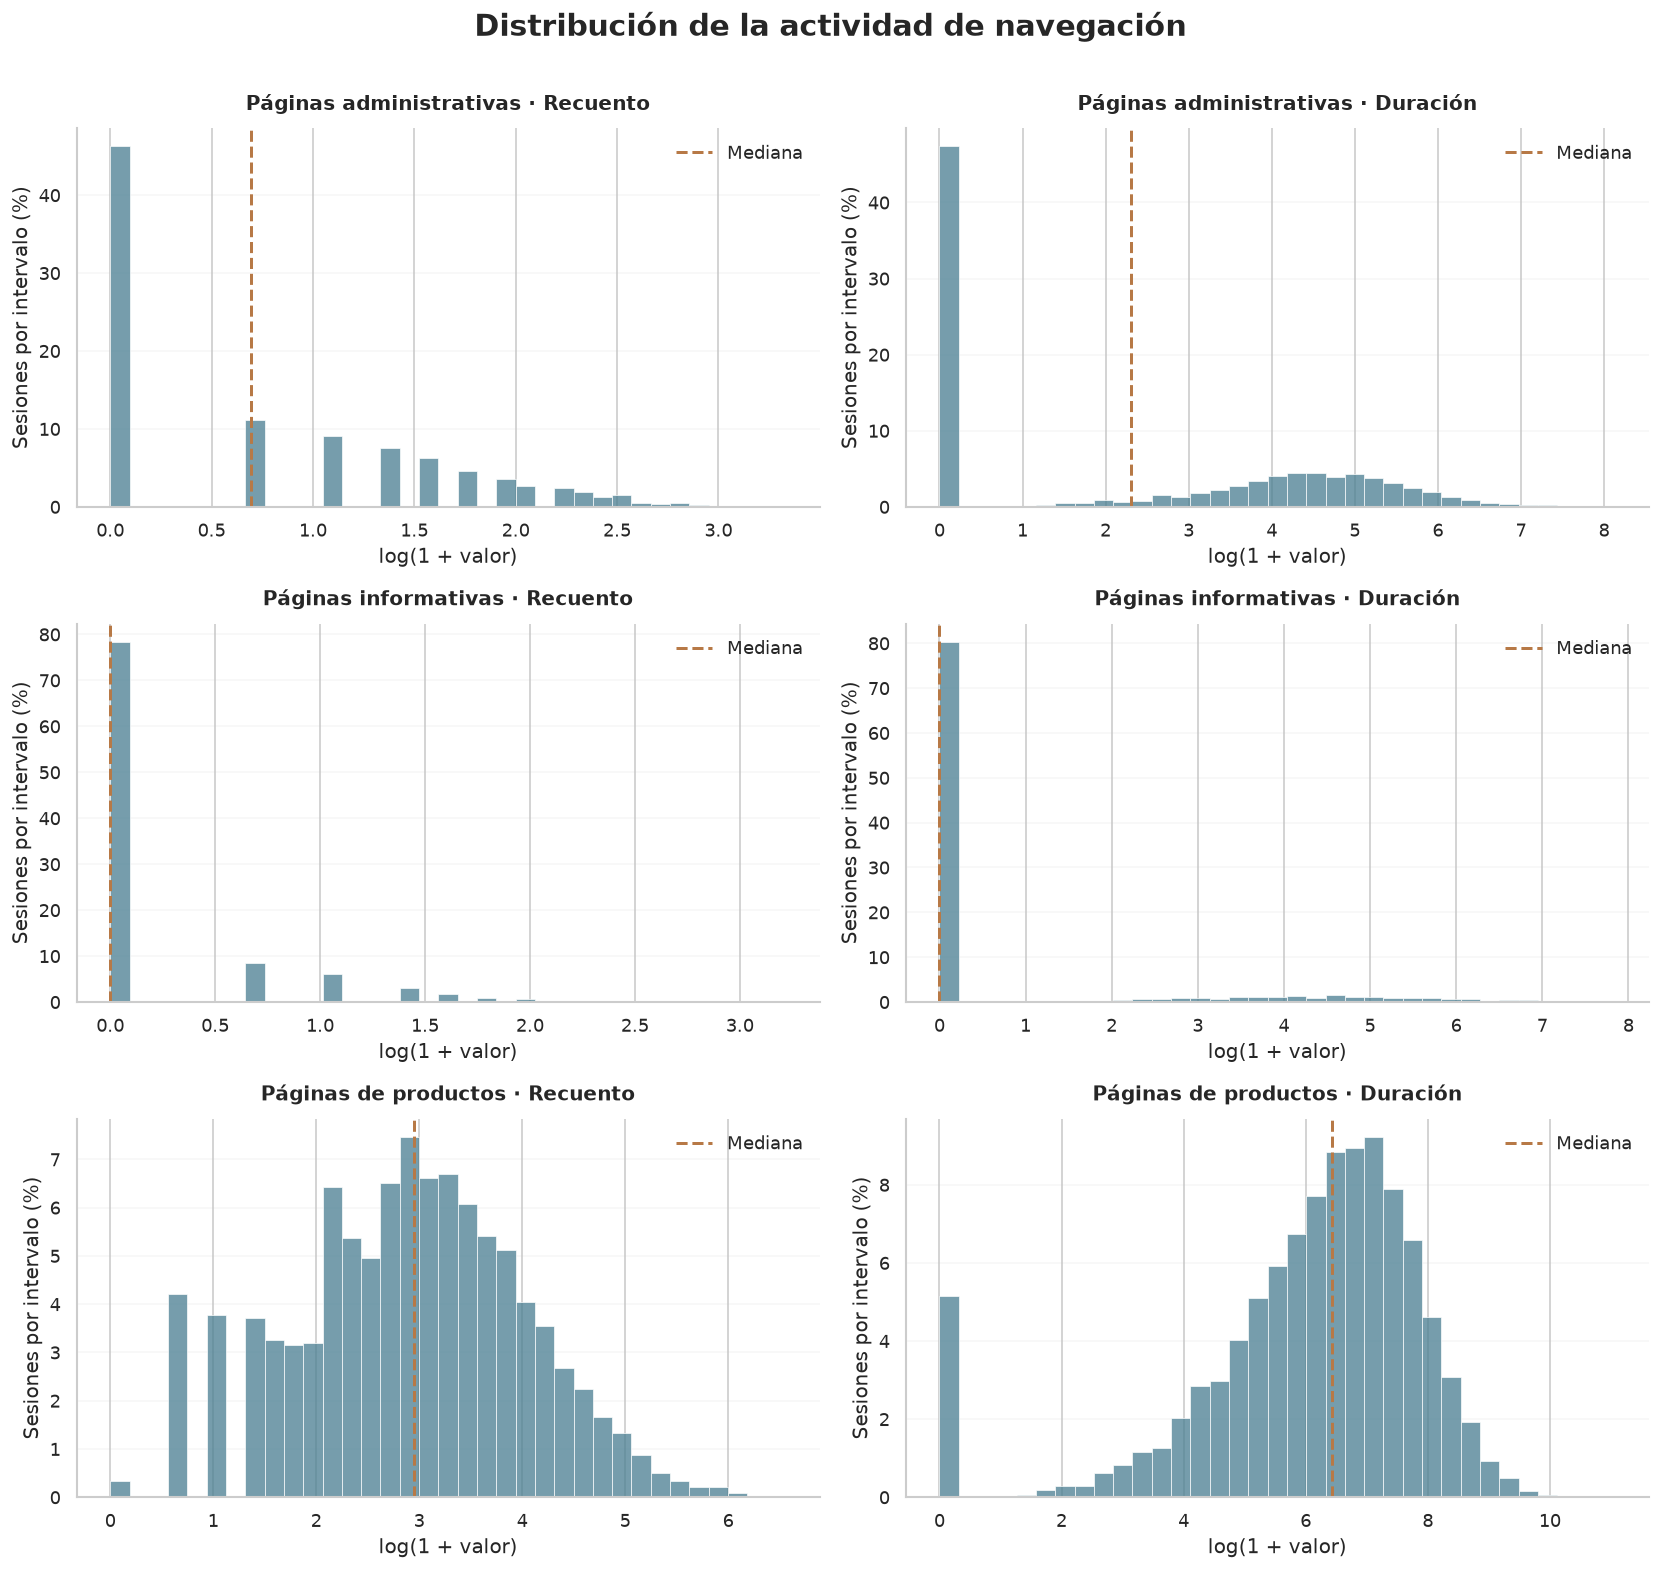

In [93]:
pares_navegacion = [
    (
        "Administrative",
        "Administrative_Duration",
        "Páginas administrativas"
    ),
    (
        "Informational",
        "Informational_Duration",
        "Páginas informativas"
    ),
    (
        "ProductRelated",
        "ProductRelated_Duration",
        "Páginas de productos"
    ),
]

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for fila, (recuento, duracion, categoria) in enumerate(pares_navegacion):

    for columna_fig, variable in enumerate([recuento, duracion]):
        ax = axes[fila, columna_fig]

        valores = np.log1p(df[variable])

        sns.histplot(
            x=valores,
            bins=35,
            stat="percent",
            color="#487D91",
            edgecolor="white",
            linewidth=0.4,
            ax=ax
        )

        ax.axvline(
            valores.median(),
            color="#B77946",
            linestyle="--",
            linewidth=1.8,
            label="Mediana"
        )

        tipo = "Recuento" if columna_fig == 0 else "Duración"

        ax.set_title(f"{categoria} · {tipo}", pad=11)
        ax.set_xlabel("log(1 + valor)")
        ax.set_ylabel("Sesiones por intervalo (%)")
        ax.legend(frameon=False)
        ax.grid(axis="y", alpha=0.15)

fig.suptitle(
    "Distribución de la actividad de navegación",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

**Interpretación**

Los tres tipos de navegación tienen comportamientos bastante diferentes.

Las **páginas informativas** destacan por su escasa presencia, cerca del 80 % de las sesiones no registra visitas ni tiempo dedicado a ellas. 

**Las páginas administrativas** también muestran una concentración considerable en cero, aunque su uso es más frecuente.

En cambio, la **navegación por productos** es mucho más habitual. Solo un 0,3 % de las sesiones registra cero páginas de productos visitados y las distribuciones de recuento y duración son bastante más amplias, con medianas de 18 páginas y 617 segundos.

También podemos ver una asimetría positiva en las variables, sobre todo en las duraciones, donde algunas sesiones presentan valores muy superiores a los habituales. La transformación logarítmica nos permite ver estas diferencias con mayor claridad sin modificar los datos originales.

### 4.3. Distribución de las tasas y de PageValues

Hemos estudiado las cuatro variables numéricas restantes: `BounceRates`, `ExitRates`, `SpecialDay` y `PageValues`.

Hemos representado las tasas en su escala original y los valores discretos de `SpecialDay` mediante un gráfico de barras.

Para `PageValues` hemos utilizado log(1 + x) solo para poder verlo de manera visual debido a su elevada concentración en cero y a la existencia de valores superiores.

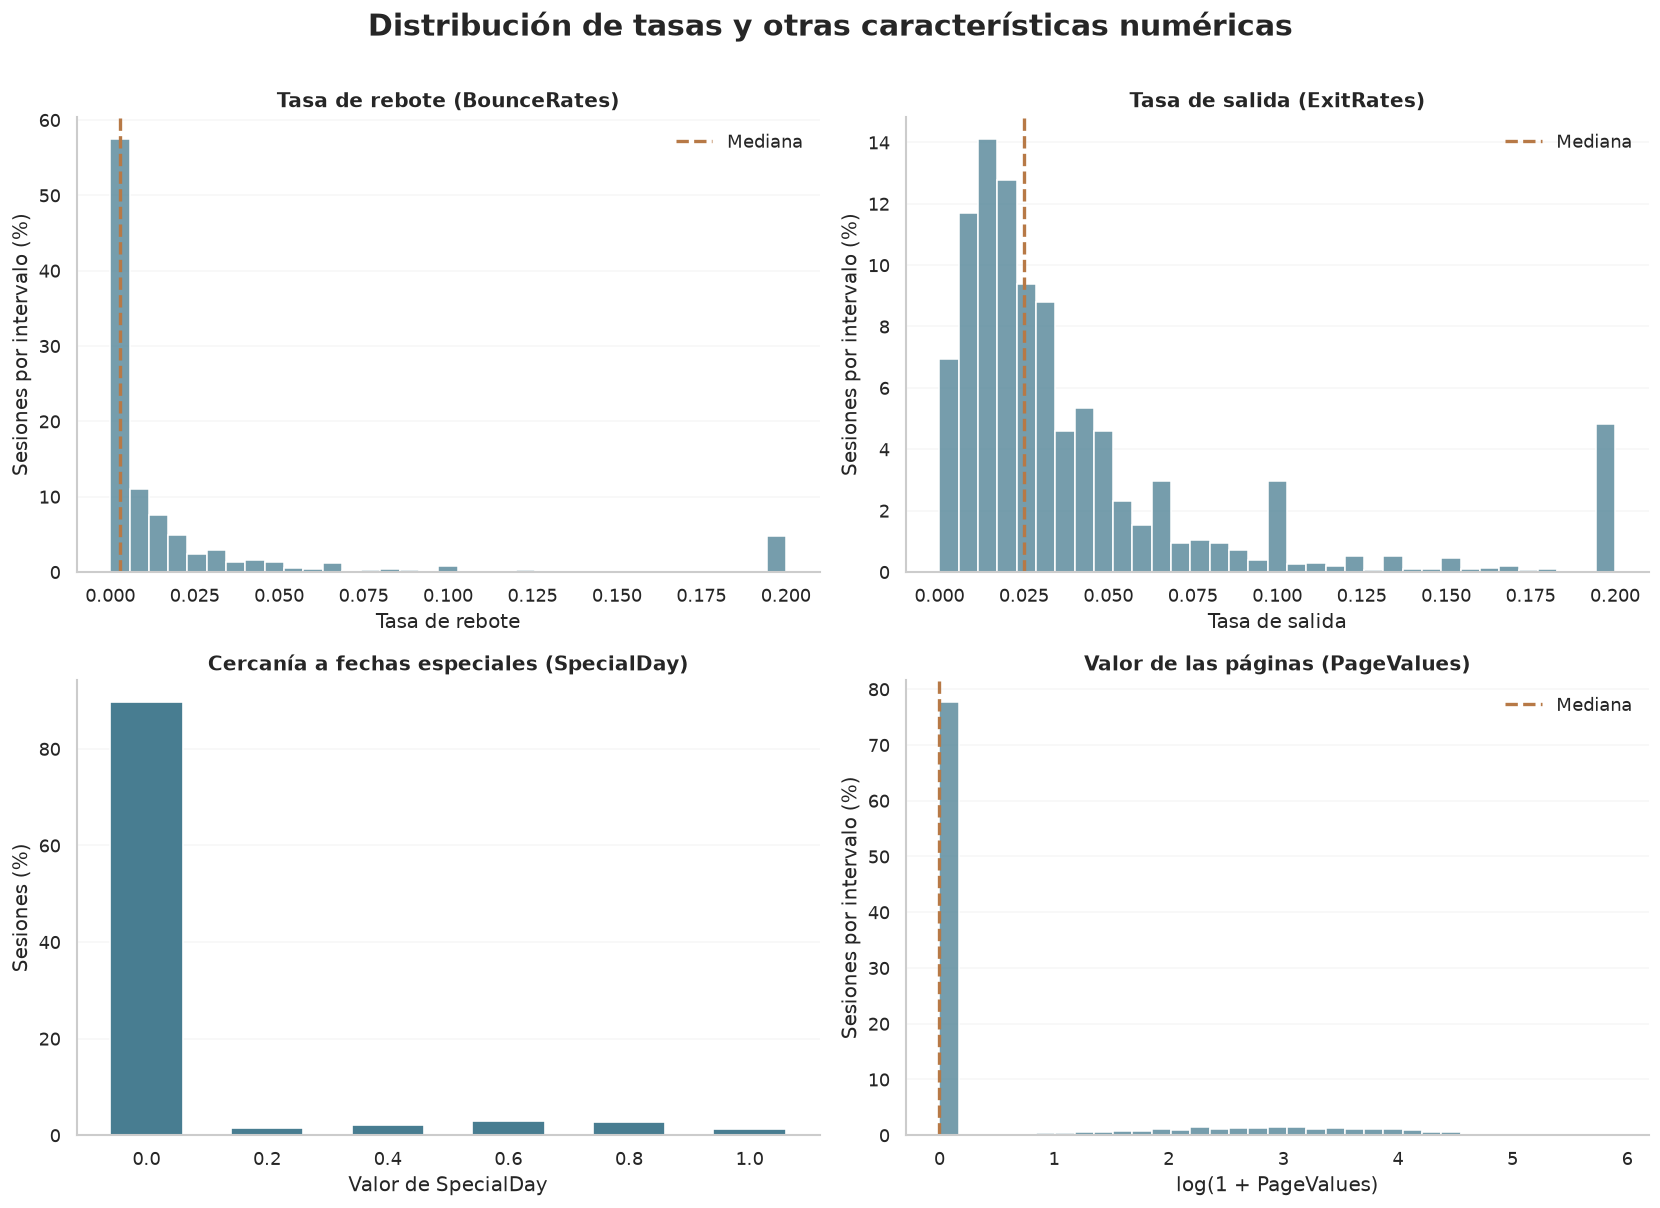

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
azul = "#487D91"
naranja = "#B77946"

# 1. BounceRates
ax = axes[0, 0]
sns.histplot(
    df["BounceRates"],
    bins=35,
    stat="percent",
    color=azul,
    edgecolor="white",
    ax=ax
)
ax.axvline(
    df["BounceRates"].median(),
    color=naranja, linestyle="--", linewidth=2,
    label="Mediana"
)
ax.set_title("Tasa de rebote (BounceRates)")
ax.set_xlabel("Tasa de rebote")
ax.set_ylabel("Sesiones por intervalo (%)")
ax.legend(frameon=False)

# 2. ExitRates
ax = axes[0, 1]
sns.histplot(
    df["ExitRates"],
    bins=35,
    stat="percent",
    color=azul,
    edgecolor="white",
    ax=ax
)
ax.axvline(
    df["ExitRates"].median(),
    color=naranja, linestyle="--", linewidth=2,
    label="Mediana"
)
ax.set_title("Tasa de salida (ExitRates)")
ax.set_xlabel("Tasa de salida")
ax.set_ylabel("Sesiones por intervalo (%)")
ax.legend(frameon=False)

# 3. SpecialDay: variable discreta
ax = axes[1, 0]
frecuencias = (
    df["SpecialDay"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

ax.bar(
    frecuencias.index,
    frecuencias.values,
    width=0.12,
    color=azul
)
ax.set_xticks(frecuencias.index)
ax.set_title("Cercanía a fechas especiales (SpecialDay)")
ax.set_xlabel("Valor de SpecialDay")
ax.set_ylabel("Sesiones (%)")

# 4. PageValues: escala logarítmica
ax = axes[1, 1]
valores_page = np.log1p(df["PageValues"])

sns.histplot(
    valores_page,
    bins=35,
    stat="percent",
    color=azul,
    edgecolor="white",
    ax=ax
)
ax.axvline(
    valores_page.median(),
    color=naranja, linestyle="--", linewidth=2,
    label="Mediana"
)
ax.set_title("Valor de las páginas (PageValues)")
ax.set_xlabel("log(1 + PageValues)")
ax.set_ylabel("Sesiones por intervalo (%)")
ax.legend(frameon=False)

# Ajustes comunes
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.15)
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Distribución de tasas y otras características numéricas",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

**Interpretación**

Las tasas de rebote y salida tienen distribuciones asimétricas, aunque con diferencias claras. Ambas tienen un máximo de 0,2 en este dataset.
- `BounceRates` está muy concentrada en cero (44,8 % de las sesiones).
- `ExitRates` muestra una mayor dispersión, especialmente en valores bajos.

`SpecialDay` tiene una distribución discreta muy desequilibrada, el valor cero representa aproximadamente el 90 % de las observaciones y los demás valores tienen una frecuencia menor.

Por último, `PageValues` tiene una alta proporción de ceros (77,9 %) y a la vez una distribución grande de valores positivos. Su mediana es cero aunque algunas sesiones alcanzan valores elevados con un máximo de 361,76.

La concentración de ceros de `PageValues` y `SpecialDay` la tendremos en cuenta  al interpretar los análisis posteriores.

### 4.4. Dispersión de las variables numéricas

Hemos utilziado diagramas de caja para examinar la mediana, el rango intercuartílico y la dispersión de seis características de navegación.

Debido a la gran asimetría de estas variables, hemos aplicado `log(1 + x)` para facilitar la visualización. Esta transformación afecta únicamente a los gráficos y no modifica los datos originales.

Los puntos situados fuera de los bigotes representan observaciones atípicas según el criterio del diagrama de caja **sobre la escala transformada**. No deben interpretarse automáticamente como errores.

En el siguiente apartado hemos analizado los valores más altos utilizando percentiles calculados sobre la escala original.

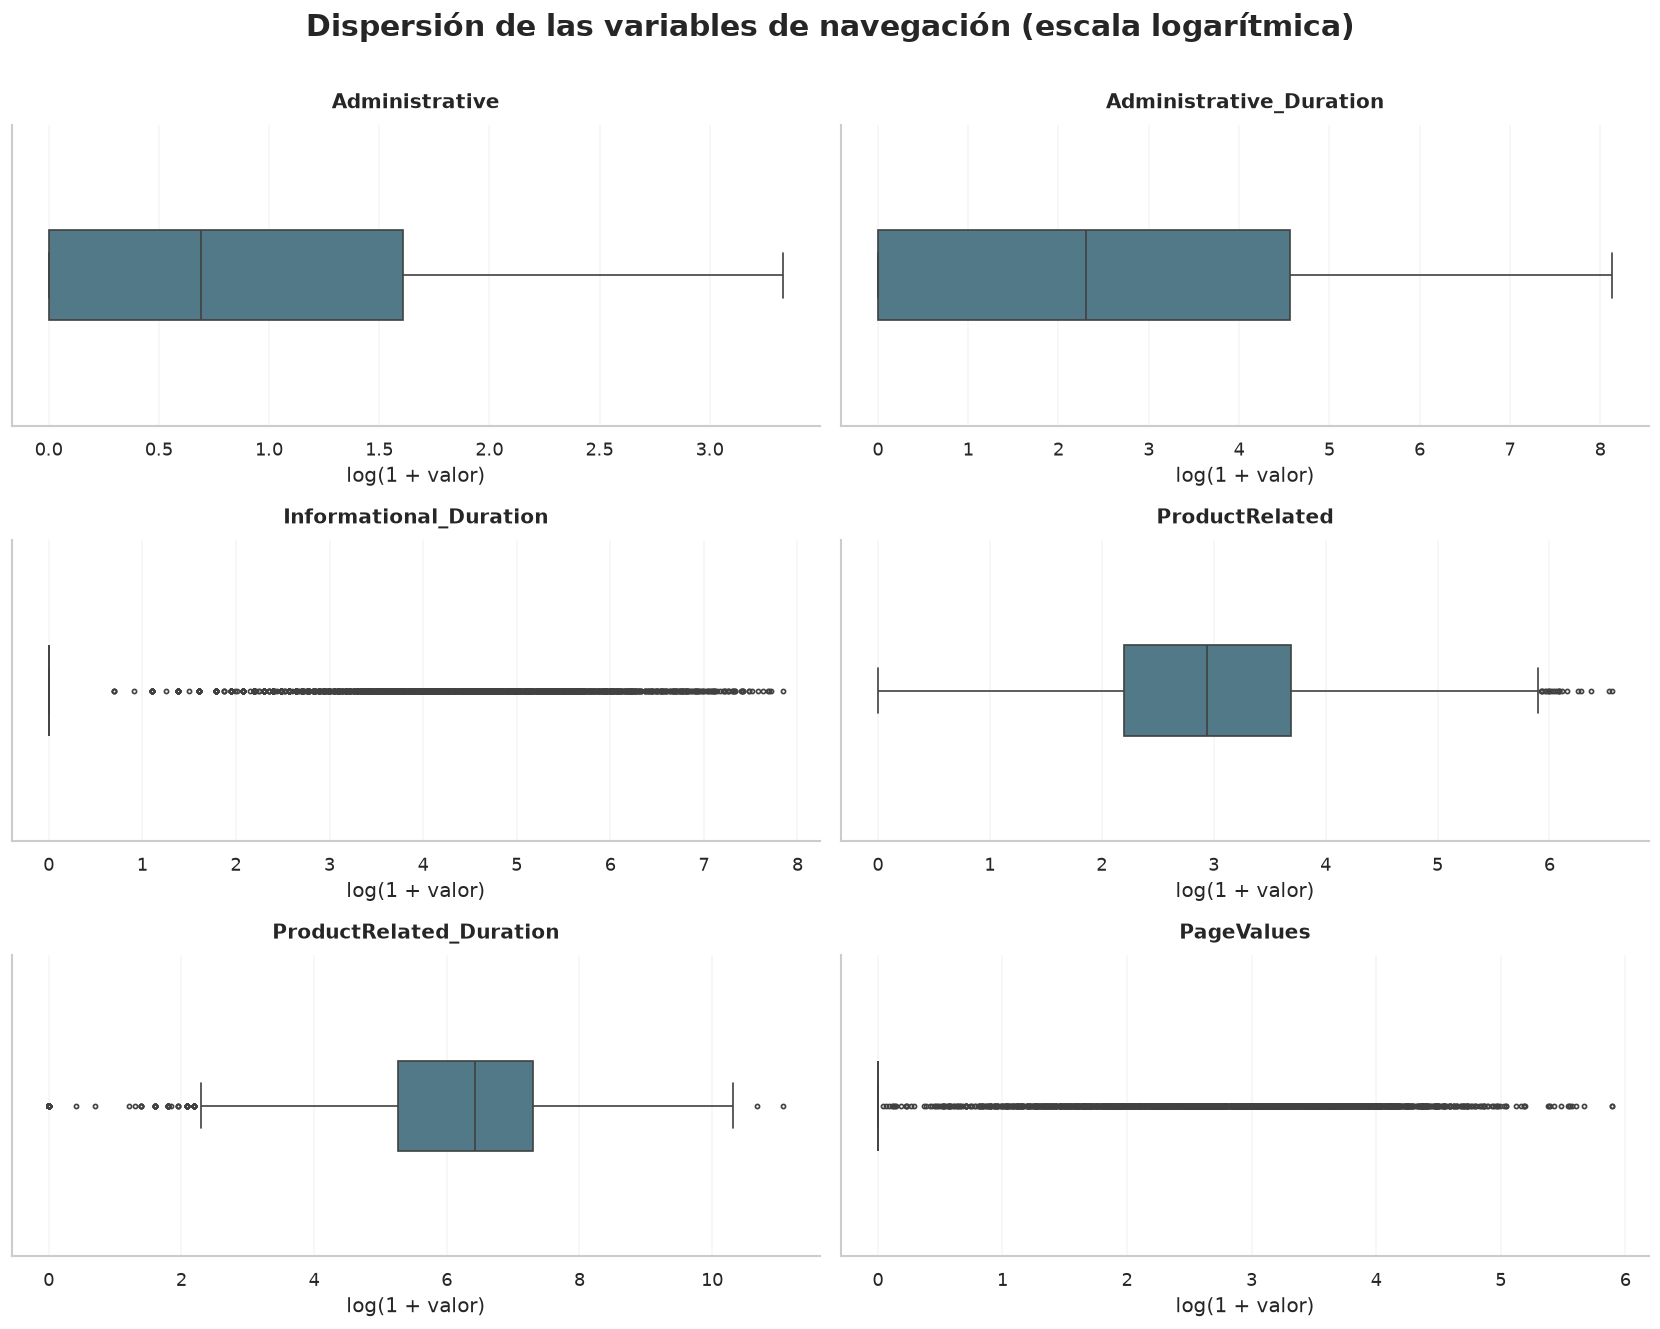

In [95]:
variables_boxplot = [
    "Administrative",
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for ax, variable in zip(axes.flat, variables_boxplot):

    valores = np.log1p(df[variable])

    sns.boxplot(
        x=valores,
        ax=ax,
        color="#487D91",
        width=0.3,
        fliersize=2.5,
        linewidth=1
    )

    ax.set_title(variable, pad=10)
    ax.set_xlabel("log(1 + valor)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.18)

fig.suptitle(
    "Dispersión de las variables de navegación (escala logarítmica)",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

**Interpretación**

Los diagramas de caja muestran diferencias en la dispersión de las variables. `ProductRelated` y `ProductRelated_Duration` tienen cajas bien definidas y observaciones alejadas de los valores centrales, especialmente en las duraciones, donde aparecen valores extremos tanto por debajo como por encima de los bigotes.

En cambio, las cajas de `Informational_Duration` y `PageValues` quedan prácticamente reducidas a una línea en cero. Esto es porque sus tres primeros cuartiles coinciden en ese valor, por lo que numerosos registros positivos aparecen como puntos atípicos.

Estos gráficos reflejan la gran asimetría de las distribuciones, aunque debemos recordar que se han construido sobre la escala `log(1 + x)`. Por tanto, los puntos atípicos se identifican respecto a esa escala y no debemos interpretarlos automáticamente como errores en los datos.

### 4.5. Análisis de valores extremos mediante percentiles

Para estudiar la magnitud de los valores más elevados, hemos comparado la mediana, los percentiles 95 y 99 y el máximo de cada variable.

Hemos preferido este enfoque al del rango intercuartílico, ya que varias características presentan una gran concentración en cero, lo que puede provocar que el
RIC sea igual a cero.

Los percentiles permiten analizar la separación entre los valores habituales y los más elevados sin considerar automáticamente estas observaciones como errores.

In [96]:
filas_extremos = []

for variable in variables_numericas:
    serie = df[variable]

    mediana = serie.median()
    p95 = serie.quantile(0.95)
    p99 = serie.quantile(0.99)
    maximo = serie.max()

    filas_extremos.append({
        "Variable": variable,
        "Mediana": mediana,
        "P95": p95,
        "P99": p99,
        "Máximo": maximo,
        "Máximo / P99": maximo / p99 if p99 > 0 else np.nan,
    })

tabla_extremos = pd.DataFrame(filas_extremos)

display(
    tabla_extremos.style
    .format({
        "Mediana": "{:,.2f}",
        "P95": "{:,.2f}",
        "P99": "{:,.2f}",
        "Máximo": "{:,.2f}",
        "Máximo / P99": "{:.2f} veces",
    }, na_rep="—")
    .background_gradient(subset=["Máximo / P99"], cmap="Blues")
    .set_caption("Comparación de percentiles y valores máximos")
)

,Variable,Mediana,P95,P99,Máximo,Máximo / P99
0,Administrative,1.00,9.00,14.00,27.00,1.93 veces
1,Administrative_Duration,9.00,353.67,845.53,"3,398.75",4.02 veces
2,Informational,0.00,3.00,6.00,24.00,4.00 veces
3,Informational_Duration,0.00,193.21,746.85,"2,549.38",3.41 veces
4,ProductRelated,18.00,109.85,221.00,705.00,3.19 veces
5,ProductRelated_Duration,617.00,"4,306.28","8,690.32","63,973.52",7.36 veces
6,BounceRates,0.00,0.15,0.20,0.20,1.00 veces
7,ExitRates,0.03,0.17,0.20,0.20,1.00 veces
8,PageValues,0.00,38.11,86.66,361.76,4.17 veces
9,SpecialDay,0.00,0.60,1.00,1.00,1.00 veces


**Interpretación**

La comparación entre percentiles y máximos confirma la existencia de valores elevados en algunas variables. El caso más llamativo es `ProductRelated_Duration`, mientras que el 99 % de las sesiones registra hasta unos 8.690 segundos, el máximo alcanza 63.974 segundos, aproximadamente **7,36 veces el percentil 99**.

También destacan `PageValues`, cuyo máximo (361,76) supera 4,17 veces su P99 (86,66), y `Administrative_Duration`, con un máximo unas cuatro veces superior a su percentil 99. Estas diferencias nos muestran que un pequeño grupo de sesiones presenta valores considerablemente más altos que el resto.

Por el contrario, variables como `BounceRates`, `ExitRates` y `SpecialDay` tienen máximos que coinciden con su P99, por lo que no presentan el mismo comportamiento en el extremo superior.

Aunque algunos registros son muy elevados, no disponemos de información suficiente para considerarlos errores. Por ello, no hemoms eliminado ni recortado automáticamente estas observaciones, sino que hemos estudiado si requieren algún tratamiento durante el modelado.

### 4.6. Conclusiones del análisis univariante

El análisis de las variables numéricas nos ha enseñado distribuciones muy heterogéneas, caracterizadas principalmente por 
- **Asimetría positiva**
- **La concentración de ceros**
- **La presencia de valores extremos**

La navegación por páginas de productos es mucho más habitual que la administrativa o informativa, aunque existe una gran variabilidad en la duración y el número de páginas visitadas.

Estas características las hemos tenido que tener en cuenta durante el modelado. Por ahora, **hemos mantenido los valores originales sin eliminar observaciones extremas** y hemos utilizado las técnicas de preprocesamiento adecuadas para cada algoritmo.

## 5. Análisis univariante de las variables categóricas

Hemos analizado la distribución de las siete variables categóricas del conjunto de entrenamiento, estudiando la frecuencia de sus categorías
y detectando posibles desequilibrios.

Aunque algunas están representadas mediante números (`Browser`,  `Region`, etc.), estos valores funcionan como códigos de categorías,
no como magnitudes cuantitativas.

### 5.1. Cardinalidad y categorías predominantes

Hemos calculado el número de categorías distintas de cada variable y la frecuencia de su categoría mayoritaria.

Este análisis nos permite identificar variables con muchas categorías y otras dominadas por un único valor, aspectos que tendremos en
cuenta durante el preprocesamiento.

In [97]:
resumen_categoricas = []

for variable in variables_categoricas:
    frecuencias = df[variable].value_counts()

    resumen_categoricas.append({
        "Variable": variable,
        "N.º categorías": df[variable].nunique(),
        "Categoría más frecuente": str(frecuencias.index[0]),
        "Frecuencia": int(frecuencias.iloc[0]),
        "Porcentaje (%)": round(
            frecuencias.iloc[0] / len(df) * 100, 2
        )
    })

tabla_categoricas = pd.DataFrame(resumen_categoricas)

display(
    tabla_categoricas.style
    .format({"Porcentaje (%)": "{:.2f}"})
    .background_gradient(
        subset=["Porcentaje (%)"],
        cmap="Blues"
    )
    .set_caption("Resumen de las variables categóricas")
)

,Variable,N.º categorías,Categoría más frecuente,Frecuencia,Porcentaje (%)
0,Month,10,May,2674,27.39
1,OperatingSystems,8,2,5237,53.64
2,Browser,13,2,6317,64.70
3,Region,9,1,3790,38.82
4,TrafficType,19,2,3111,31.86
5,VisitorType,3,Returning_Visitor,8347,85.49
6,Weekend,2,False,7480,76.61


**Interpretación**

Las variables categóricas presentan cardinalidades muy diferentes. `TrafficType` es la que tiene más categorías (19), luego va `Browser` (13) y por último `Weekend` solo tiene dos.

También hemos observado una concentración importante en determinadas categorías. Destacan `VisitorType`, donde el 85,49 % de las sesiones corresponden a visitantes recurrentes, y `Browser`, cuyo código 2 representa el 64,70 %.

### 5.2. Distribución temporal y perfil del visitante

Hemos exminado cómo se distribuyen las sesiones según el mes, el tipo de visitante y si la visita se produjo durante el fin de semana.

Hemos representado sus frecuencias relativas para facilitar la comparación entre categorías y hemos utilziado el orden cronológico en los meses.

Por ahora hemos analizado únicamente la presencia de cada categoría sin estudiar todavía su relación con la compra.

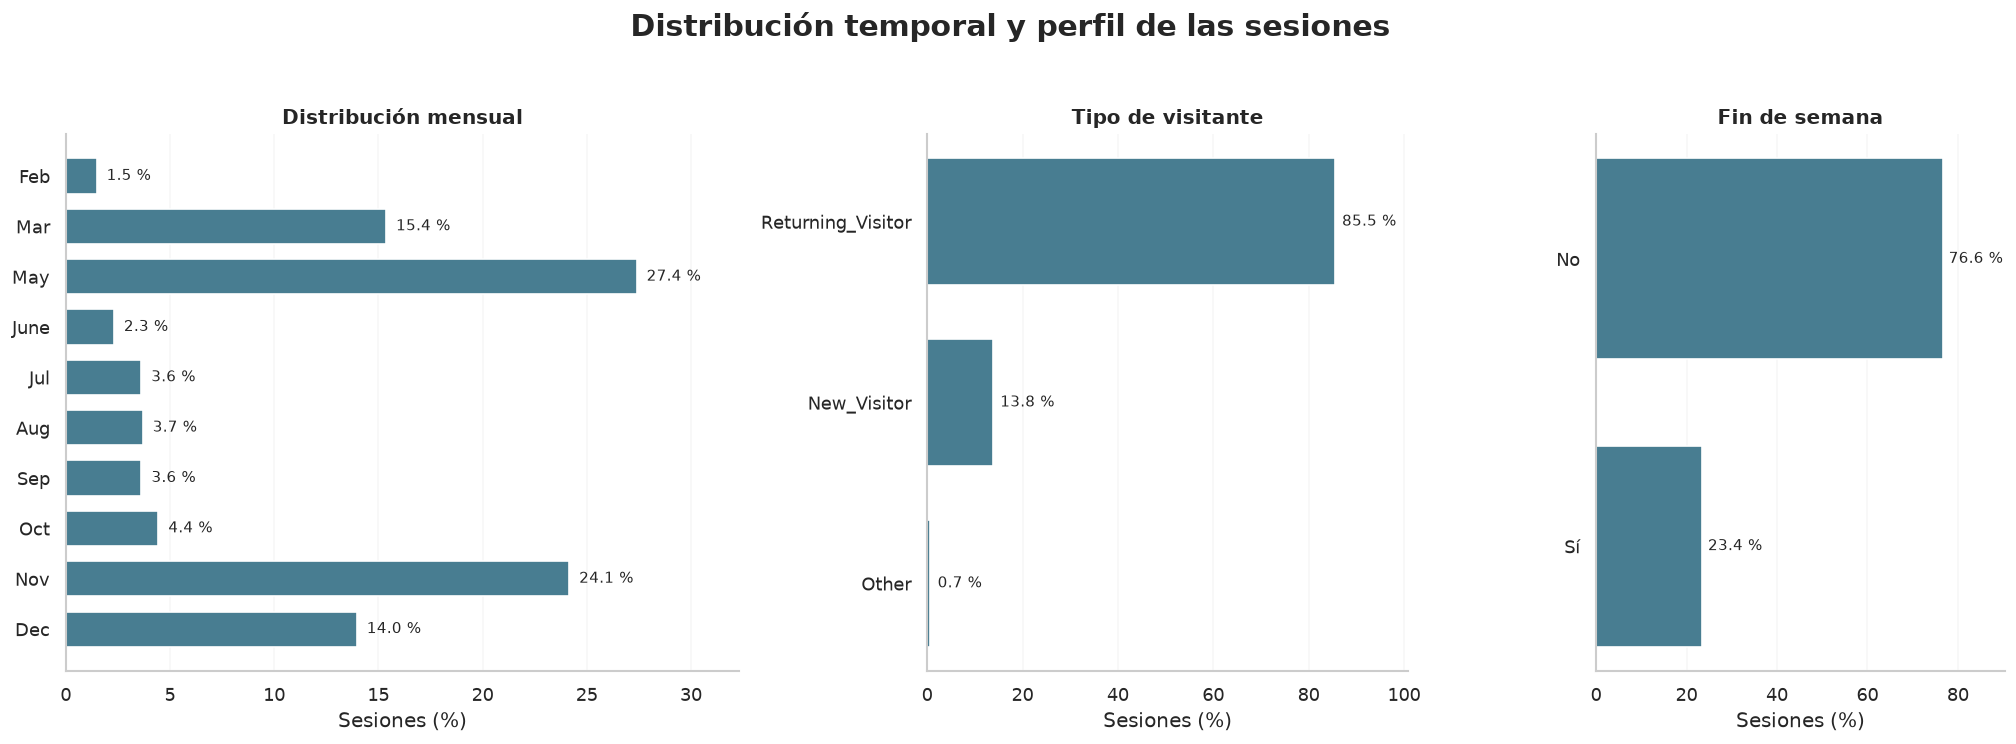

In [98]:
def grafico_categorias(ax, variable, orden=None):
    frecuencias = df[variable].value_counts(normalize=True) * 100

    if orden is not None:
        categorias = [v for v in orden if v in frecuencias.index]
        frecuencias = frecuencias.reindex(categorias)
    else:
        frecuencias = frecuencias.sort_values(ascending=False)

    etiquetas = [
        {True: "Sí", False: "No"}.get(v, str(v))
        if variable == "Weekend" else str(v)
        for v in frecuencias.index
    ]

    posiciones = np.arange(len(frecuencias))

    ax.barh(
        posiciones,
        frecuencias.values,
        color="#487D91",
        height=0.7
    )

    ax.set_yticks(posiciones, labels=etiquetas)
    ax.invert_yaxis()

    limite = max(frecuencias.max() * 1.18, 1)
    ax.set_xlim(0, limite)

    for i, porcentaje in enumerate(frecuencias.values):
        ax.text(
            porcentaje + limite * 0.015,
            i,
            f"{porcentaje:.1f} %",
            va="center",
            fontsize=9
        )

    ax.set_title(variable, pad=12, fontweight="bold")
    ax.set_xlabel("Sesiones (%)")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)


# --- Distribución por mes y perfil de visitante ---

orden_meses = [
    "Jan", "Feb", "Mar", "Apr", "May", "June",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(
    1, 3, figsize=(17, 6),
    gridspec_kw={"width_ratios": [1.4, 1, 0.85]}
)

grafico_categorias(axes[0], "Month", orden=orden_meses)
grafico_categorias(axes[1], "VisitorType")
grafico_categorias(axes[2], "Weekend", orden=[False, True])

axes[0].set_title("Distribución mensual")
axes[1].set_title("Tipo de visitante")
axes[2].set_title("Fin de semana")

fig.suptitle(
    "Distribución temporal y perfil de las sesiones",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

**Interpretación**

La distribución mensual no es uniforme. 

**Mayo (27,4 %) y noviembre (24,1 %) concentran más de la mitad de las sesiones**, seguidos de marzo (15,4 %) y diciembre (14 %).

En cambio, otros meses tienen una presencia mucho menor y **enero y abril no aparecen** en el dataset.

Respecto al perfil del visitante, predominan los usuarios recurrentes (`Returning_Visitor`), con un 85,5 % de las sesiones, frente al 13,8 % de visitantes nuevos.

Por último, el 76,6 % de las sesiones de registra son entre semana y el 23,4 % son los fines de semana.

### 5.3. Distribución de las categorías codificadas

Hemos estudiado las cuatro características categóricas representadas mediante códigos numéricos: sistema operativo, navegador, región y tipo de tráfico.

Hemos utilziado gráficos de barras para comparar las frecuencias de cada categoría. Los códigos se interpretan como identificadores.

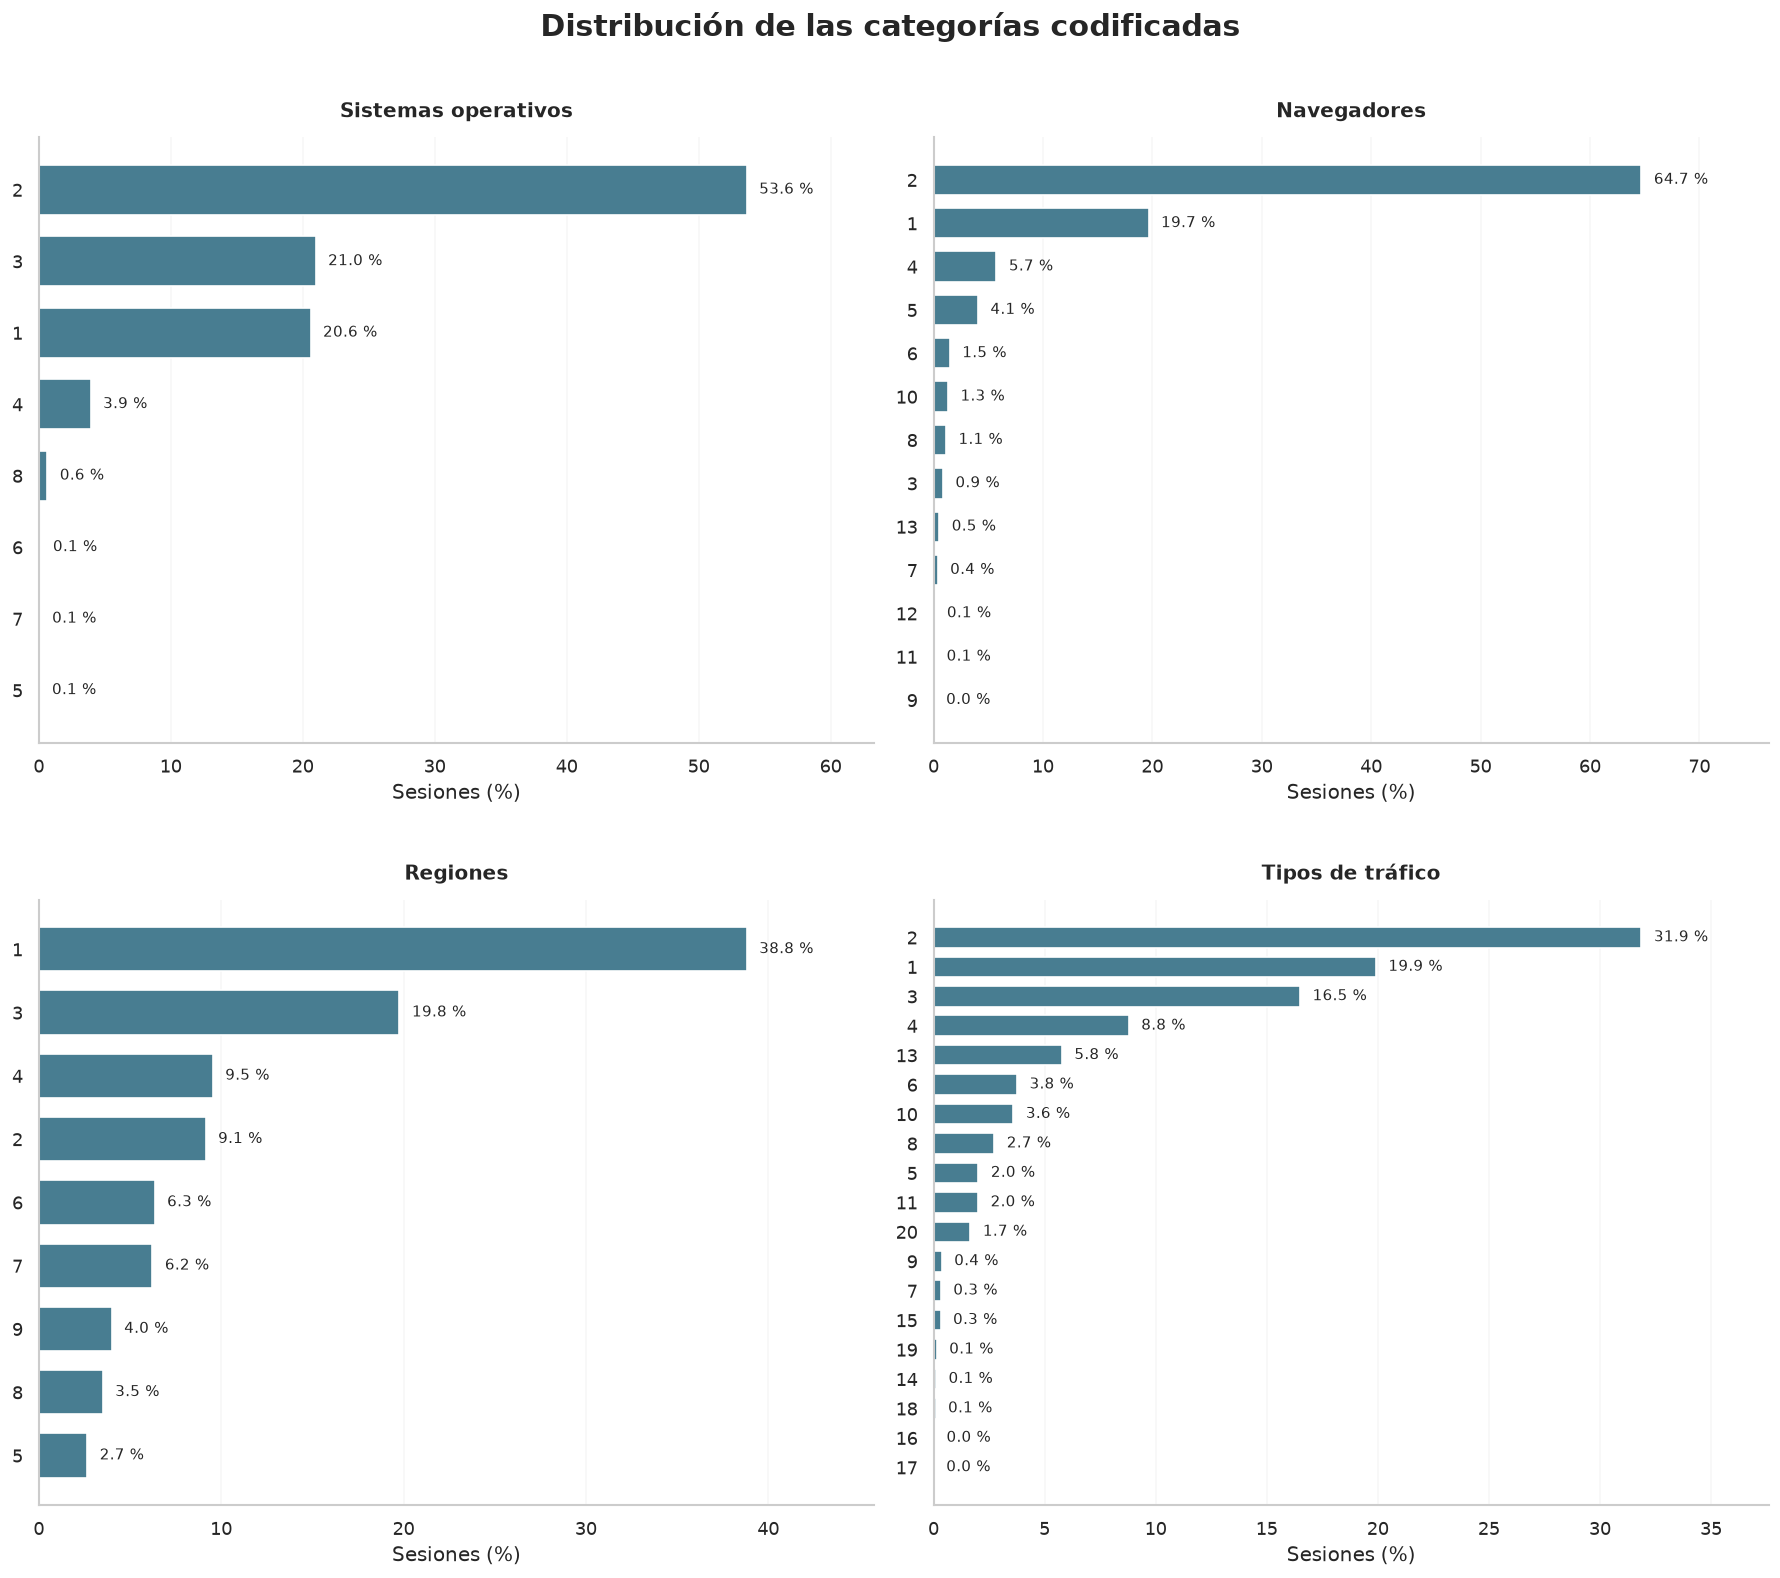

In [99]:
categorias_codificadas = [
    ("OperatingSystems", "Sistemas operativos"),
    ("Browser", "Navegadores"),
    ("Region", "Regiones"),
    ("TrafficType", "Tipos de tráfico"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 13))

for ax, (variable, titulo) in zip(
    axes.flat, categorias_codificadas
):
    grafico_categorias(ax, variable)
    ax.set_title(titulo, pad=12)

fig.suptitle(
    "Distribución de las categorías codificadas",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(h_pad=3)
plt.show()

**Interpretación**

Las categorías codificadas también presentan distribuciones desiguales. En `OperatingSystems`, los códigos 2, 3 y 1 concentran aproximadamente el 95 % de las sesiones. La concentración es todavía más marcada en `Browser`, donde el código 2 representa el 64,7 % y el código 1 otro 19,7 %.

`Region` presenta una distribución más repartida, aunque los códigos 1 y 3 reúnen el 58,6 % de las observaciones.

Por último, `TrafficType` muestra una mayor diversidad con 19 categorías. Los códigos 2, 1 y 3 concentran el 68,3 % de las sesiones auqnue numerosas categorías tienen frecuencias inferiores al 1 %.

### 5.4. Conclusiones del análisis univariante categórico

El análisis de las variables categóricas ha revelado tres características principales:

- **Concentración temporal:** mayo y noviembre acumulan más de la mitad de las sesiones.
- **Falta de meses:** enero y abril.
- **Predominio de determinados perfiles:** la mayoría de las visitas corresponde a usuarios recurrentes y se produce entre semana.
- **Desequilibrio entre categorías:** existen códigos muy frecuentes y otros con muy pocas observaciones, especialmente en `Browser` y `TrafficType`.

Estas diferencias van a condicionar bastante lo que hemos hecho en el preprocesamiento, especialmente al codificar las variables categóricas mediante One-Hot Encoding.

## 6. Análisis bivariante: relación con la compra

Hemos analizado la relación de cada variable con `Revenue`, nuestra variable objetivo.

Lo que buscamos son diferencias entre las sesiones que terminan en compra y las que no. También posibles asociaciones entre las
características y la conversión.

Este análisis es exploratorio, entonces no debemos sacar una conclusiones finales de esto.

### 6.1. Conversión según el mes y el perfil del visitante

Hemos analizado las tasas de conversión según `Month`, `VisitorType` y `Weekend`, comparándolas con la tasa global del entrenamiento.

La tasa de conversión de una categoría se calcula como el porcentaje de sesiones de esa categoría que termina en compra.

También hemos mostrado el número de sesiones de cada grupo, ya que los porcentajes obtenidos a partir de grupos pequeños pueden
ser menos representativos.

In [100]:
tasa_global = df["Revenue"].mean() * 100

def calcular_conversion(variable, orden=None):
    tabla = (
        df.groupby(variable, observed=True)["Revenue"]
        .agg(Sesiones="size", Compras="sum", Tasa="mean")
        .reset_index()
    )

    tabla["Tasa"] *= 100

    if orden is not None:
        tabla[variable] = pd.Categorical(
            tabla[variable],
            categories=orden,
            ordered=True
        )
        tabla = tabla.sort_values(variable)
    else:
        tabla = tabla.sort_values("Sesiones", ascending=False)

    return tabla.reset_index(drop=True)


conversion_mes = calcular_conversion("Month", orden_meses)
conversion_visitante = calcular_conversion("VisitorType")
conversion_weekend = calcular_conversion("Weekend", [False, True])

print(f"Tasa de conversión global: {tasa_global:.2f} %")
display(conversion_mes)
display(conversion_visitante)
display(conversion_weekend)

Tasa de conversión global: 15.63 %


,Month,Sesiones,Compras,Tasa
0,Feb,144,3,2.083333
1,Mar,1500,159,10.600000
2,May,2674,286,10.695587
3,June,225,23,10.222222
4,Jul,353,51,14.447592
5,Aug,360,62,17.222222
6,Sep,354,67,18.926554
7,Oct,433,97,22.401848
8,Nov,2358,599,25.402884
9,Dec,1363,179,13.132795


,VisitorType,Sesiones,Compras,Tasa
0,Returning_Visitor,8347,1185,14.196717
1,New_Visitor,1349,325,24.091920
2,Other,68,16,23.529412


,Weekend,Sesiones,Compras,Tasa
0,False,7480,1127,15.066845
1,True,2284,399,17.469352


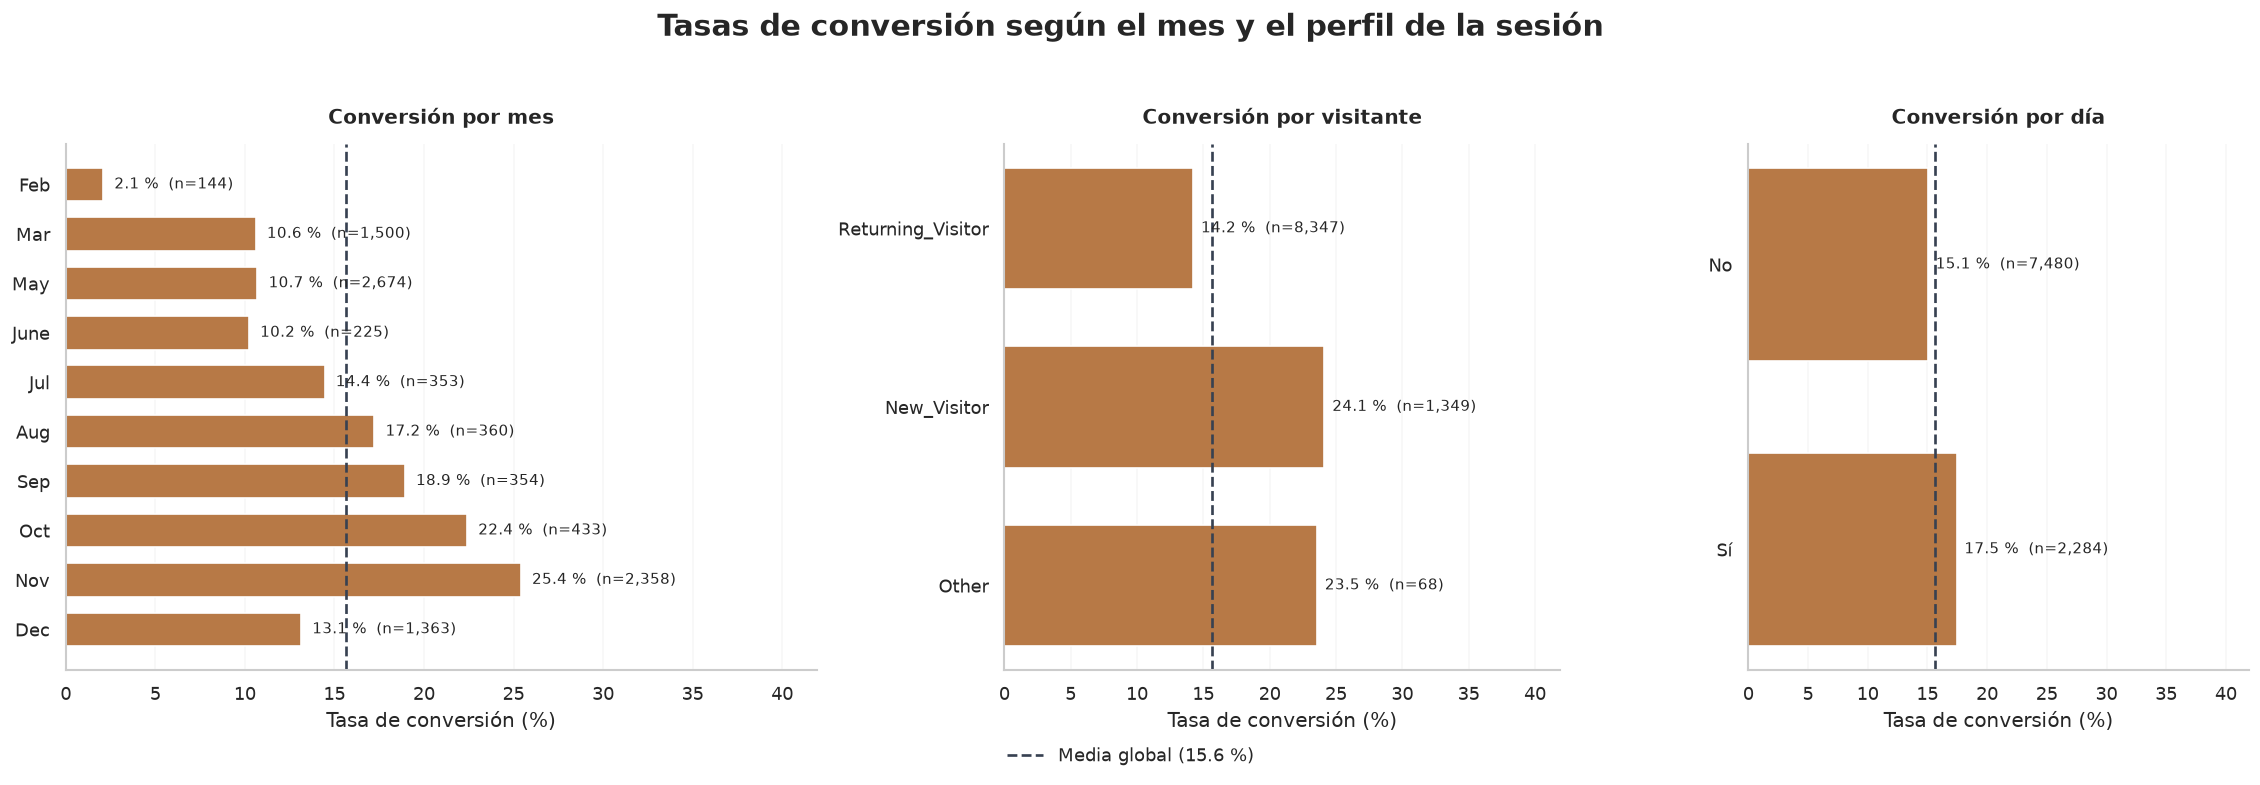

In [101]:
def graficar_conversion(ax, tabla, variable, titulo, limite_x):
    posiciones = np.arange(len(tabla))

    etiquetas = [
        {True: "Sí", False: "No"}.get(v, str(v))
        if variable == "Weekend" else str(v)
        for v in tabla[variable]
    ]

    ax.barh(
        posiciones,
        tabla["Tasa"],
        color="#B77946",
        height=0.68
    )

    ax.axvline(
        tasa_global,
        color="#374151",
        linestyle="--",
        linewidth=1.6,
        label=f"Media global ({tasa_global:.1f} %)"
    )

    ax.set_yticks(posiciones, labels=etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(0, limite_x)

    for i, fila in tabla.reset_index(drop=True).iterrows():
        ax.text(
            fila["Tasa"] + limite_x * 0.015,
            i,
            f'{fila["Tasa"]:.1f} %  (n={fila["Sesiones"]:,})',
            va="center",
            fontsize=9
        )

    ax.set_title(titulo, pad=12)
    ax.set_xlabel("Tasa de conversión (%)")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)


limite = max(
    conversion_mes["Tasa"].max(),
    conversion_visitante["Tasa"].max(),
    conversion_weekend["Tasa"].max(),
    tasa_global
) * 1.65

fig, axes = plt.subplots(
    1, 3, figsize=(19, 6),
    gridspec_kw={"width_ratios": [1.35, 1, 0.9]}
)

graficar_conversion(
    axes[0], conversion_mes, "Month",
    "Conversión por mes", limite
)
graficar_conversion(
    axes[1], conversion_visitante, "VisitorType",
    "Conversión por visitante", limite
)
graficar_conversion(
    axes[2], conversion_weekend, "Weekend",
    "Conversión por día", limite
)

fig.suptitle(
    "Tasas de conversión según el mes y el perfil de la sesión",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    frameon=False
)

plt.tight_layout()
plt.show()

**Interpretación**

La tasa de conversión presenta diferencias importantes entre meses.
- **Noviembre alcanza el 25,4 %**, seguido de octubre (22,4 %), ambos por encima de la media global (15,6 %). 
- Mayo aunque concentra el mayor número de sesiones, registra una conversión del 10,7 %. Un mayor volumen de visitas no implica necesariamente una mayor proporción de compras.

También destaca el tipo de visitante: 
- Usuarios nuevos presentan una tasa de conversión del **24,1 %**.
- Usuarios recurrentes: 14,2 % de los recurrentes, a pesar de que representan la gran mayoría de las sesiones.

Por último, las visitas durante el fin de semana muestran una conversión ligeramente superior (17,5 %) a las realizadas entre semana (15,1 %).

### 6.2. Conversión según las categorías codificadas

Hemos comparado las tasas de conversión de `OperatingSystems`, `Browser`, `Region` y `TrafficType`, tomando como referencia
la tasa global de compra.

Debido a que algunas categorías tienen muy pocas observaciones, hemos representado únicamente aquellas con al menos 50 sesiones.
Los grupos restantes se conservan en los datos y pueden consultarse en las tablas.

In [102]:
categorias_codificadas = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

MIN_SESIONES = 50

tablas_conversion = {
    variable: calcular_conversion(variable)
    for variable in categorias_codificadas
}

for variable, tabla in tablas_conversion.items():
    print(f"\n{variable}")
    print(
        f"Categorías con menos de {MIN_SESIONES} sesiones: "
        f"{(tabla['Sesiones'] < MIN_SESIONES).sum()}"
    )

    display(
        tabla.style.format({
            "Tasa": "{:.2f} %"
        })
    )


OperatingSystems
Categorías con menos de 50 sesiones: 3


,OperatingSystems,Sesiones,Compras,Tasa
0,2,5237,923,17.62 %
1,3,2048,219,10.69 %
2,1,2010,295,14.68 %
3,4,383,70,18.28 %
4,8,63,15,23.81 %
5,6,12,2,16.67 %
6,7,6,1,16.67 %
7,5,5,1,20.00 %



Browser
Categorías con menos de 50 sesiones: 4


,Browser,Sesiones,Compras,Tasa
0,2,6317,985,15.59 %
1,1,1919,285,14.85 %
2,4,561,99,17.65 %
3,5,396,72,18.18 %
4,6,145,16,11.03 %
5,10,129,26,20.16 %
6,8,111,18,16.22 %
7,3,84,4,4.76 %
8,13,51,16,31.37 %
9,7,37,2,5.41 %



Region
Categorías con menos de 50 sesiones: 0


,Region,Sesiones,Compras,Tasa
0,1,3790,615,16.23 %
1,3,1931,284,14.71 %
2,4,931,133,14.29 %
3,2,893,149,16.69 %
4,6,620,93,15.00 %
5,7,608,96,15.79 %
6,9,390,65,16.67 %
7,8,342,46,13.45 %
8,5,259,45,17.37 %



TrafficType
Categorías con menos de 50 sesiones: 8


,TrafficType,Sesiones,Compras,Tasa
0,2,3111,669,21.50 %
1,1,1944,210,10.80 %
2,3,1611,147,9.12 %
3,4,858,130,15.15 %
4,13,564,34,6.03 %
5,6,367,44,11.99 %
6,10,351,79,22.51 %
7,8,267,74,27.72 %
8,5,197,44,22.34 %
9,11,196,36,18.37 %


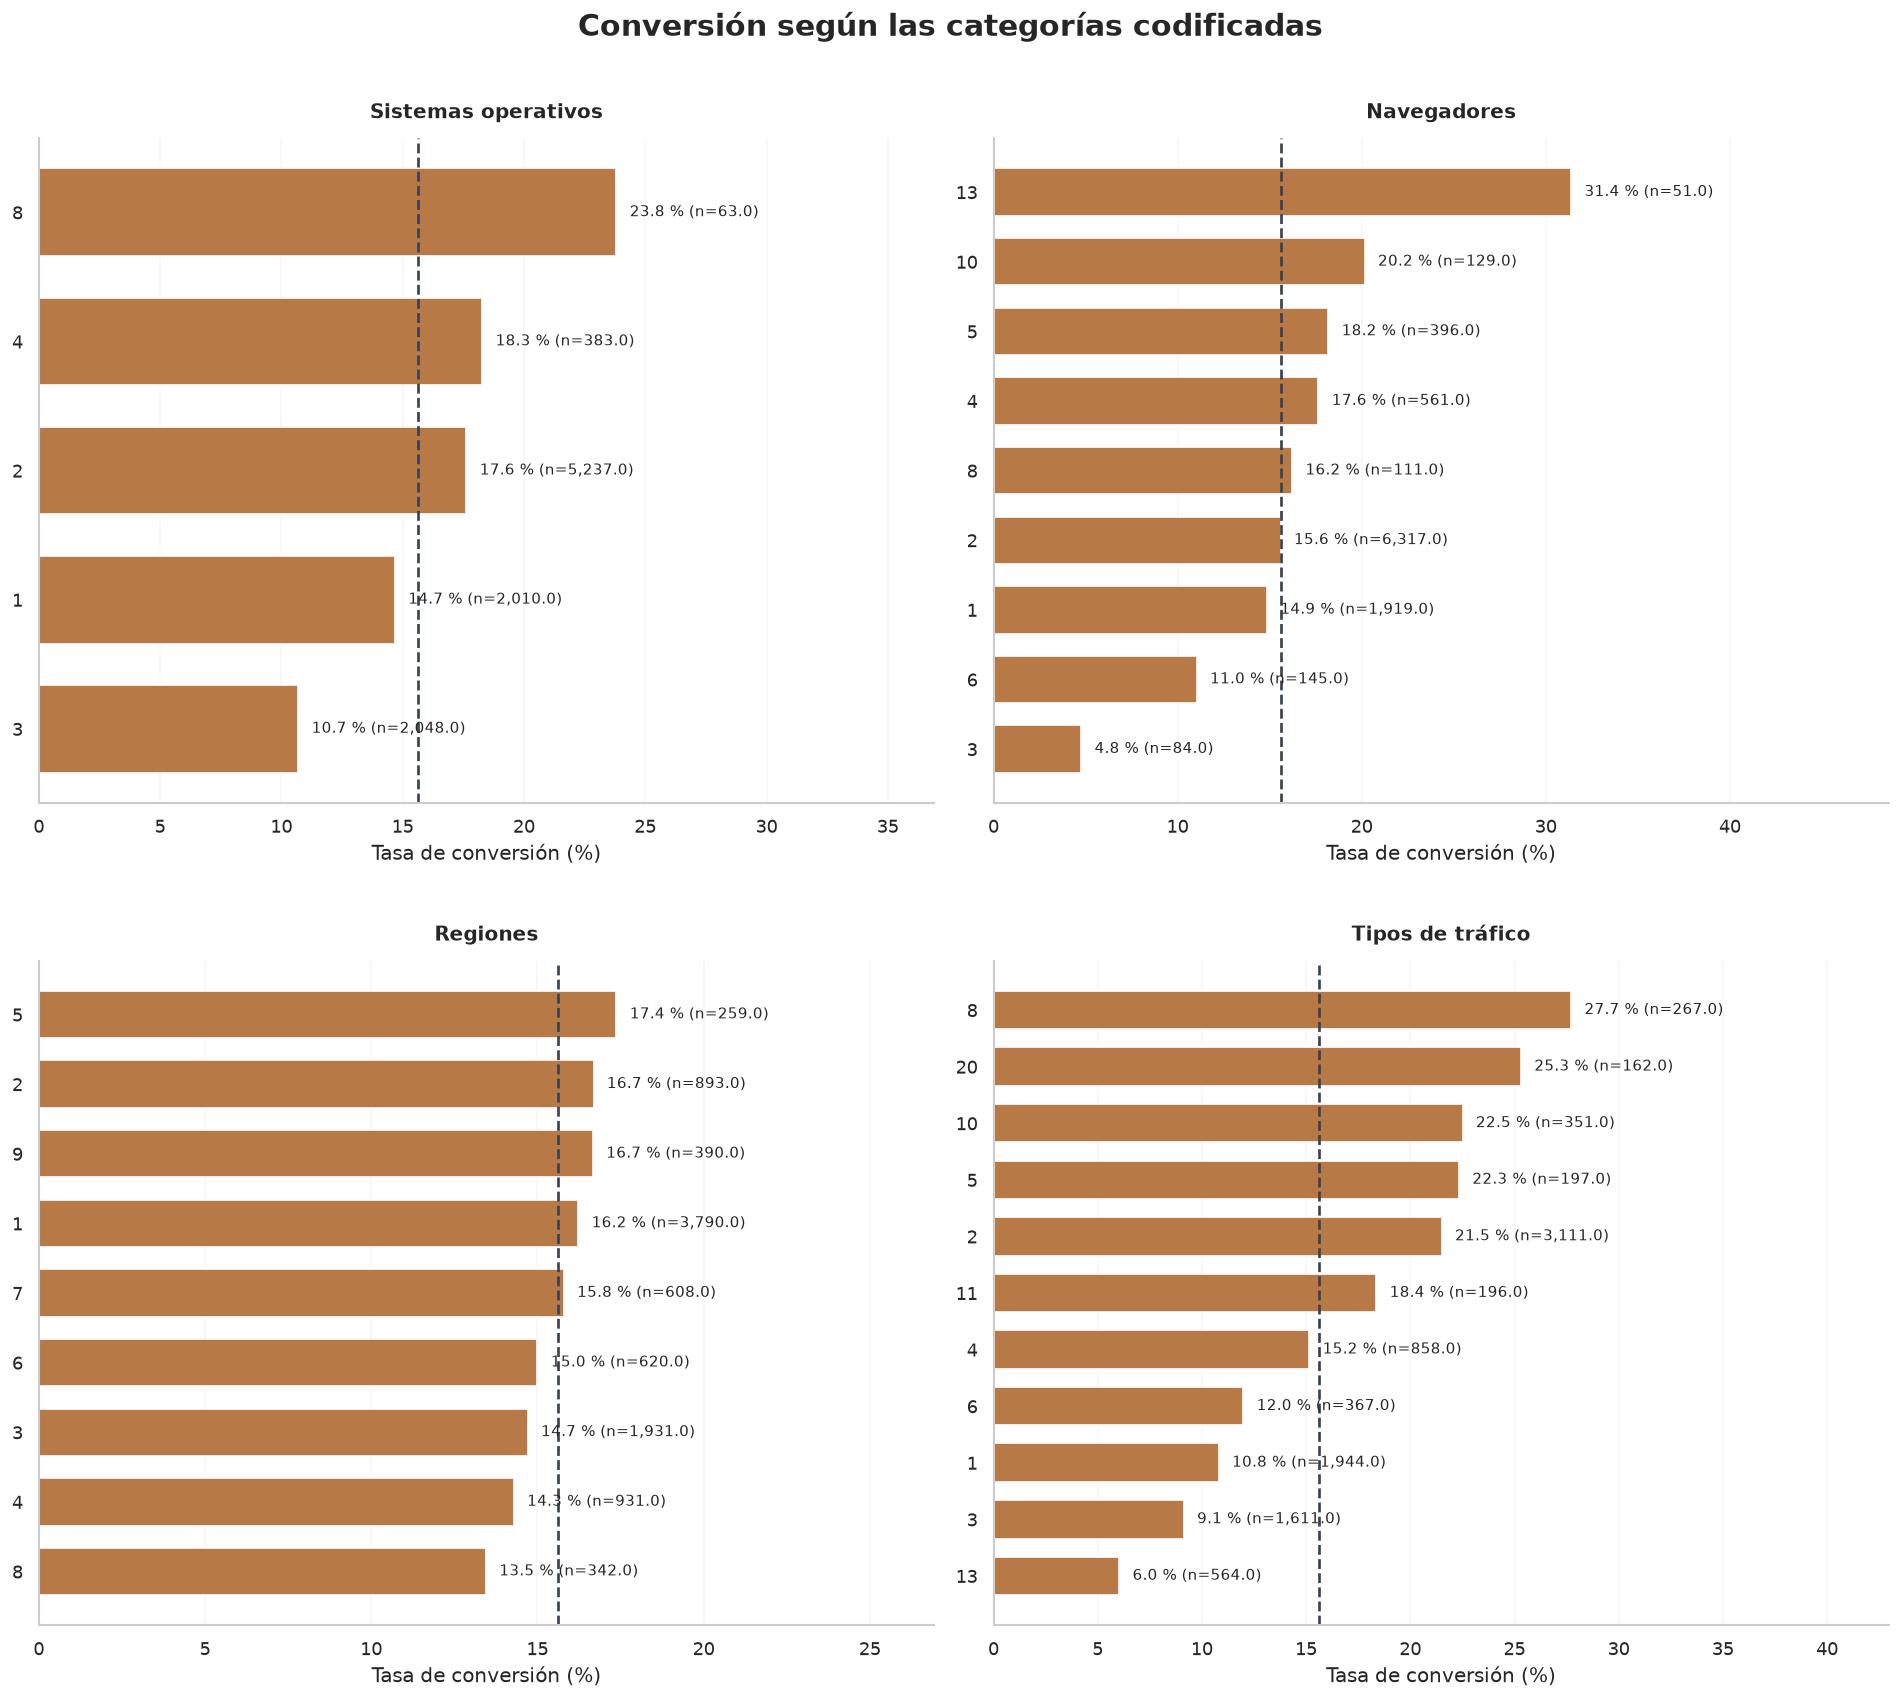

In [103]:
titulos = {
    "OperatingSystems": "Sistemas operativos",
    "Browser": "Navegadores",
    "Region": "Regiones",
    "TrafficType": "Tipos de tráfico"
}

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, variable in zip(axes.flat, categorias_codificadas):

    tabla = tablas_conversion[variable].copy()
    tabla = tabla[tabla["Sesiones"] >= MIN_SESIONES]
    tabla = tabla.sort_values("Tasa", ascending=False)

    posiciones = np.arange(len(tabla))
    limite = max(tabla["Tasa"].max(), tasa_global) * 1.55

    ax.barh(
        posiciones,
        tabla["Tasa"],
        color="#B77946",
        height=0.68
    )

    ax.axvline(
        tasa_global,
        color="#374151",
        linestyle="--",
        linewidth=1.6
    )

    ax.set_yticks(
        posiciones,
        labels=tabla[variable].astype(str)
    )
    ax.invert_yaxis()
    ax.set_xlim(0, limite)

    for i, (_, fila) in enumerate(tabla.iterrows()):
        ax.text(
            fila["Tasa"] + limite * 0.015,
            i,
            f'{fila["Tasa"]:.1f} % (n={fila["Sesiones"]:,})',
            va="center",
            fontsize=9
        )

    ax.set_title(titulos[variable], pad=12)
    ax.set_xlabel("Tasa de conversión (%)")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Conversión según las categorías codificadas",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(h_pad=3)
plt.show()

**Interpretación**

En `OperatingSystems`, el código 2 registra un 17,6 % de conversión, frente al 10,7 % del código 3. En `Browser` destaca el código 13 con un 31,4 %, aunque solo cuenta con 51 sesiones, por lo que debemos interpretar ese resultado con cuidado.

Las diferencias entre regiones son menores, con tasas comprendidas entre el 13,5 % y el 17,4 %.

En cambio, **`TrafficType` presenta variaciones mayores**: los códigos 8 y 20 superan el 25 % de conversión, mientras que los códigos 3 y 13 se sitúan en el 9,1 % y el 6 %, respectivamente.

Estos resultados sugieren que el origen del tráfico podría estar relacionado con la compra pero las categorías menos representadas pueden presentar tasas menos estables.

### 6.3. Diferencias numéricas entre compradores y no compradores

Hemos comparado las diez características numéricas según el resultado de la sesión (`Revenue`).

Hemos analizado las diferencias en las distribuciones y los estadísticos de ambos grupos para identificar posibles asociaciones con la compra.

Dado que las clases están desequilibradas, utilizaremos representaciones que permitan comparar sus distribuciones
independientemente del número de sesiones de cada grupo.

#### 6.3.1. Comparación de medias y medianas

Hemos calculado las medias y medianas de cada característica para las sesiones con y sin compra.

La comparación de ambas medidas es útil en este dataset, ya que muchas variables presentan distribuciones
asimétricas y valores extremos.

In [104]:
resumen_clases = pd.DataFrame(index=variables_numericas)

for clase, etiqueta in [(False, "No compra"), (True, "Compra")]:
    grupo = df.loc[df["Revenue"] == clase, variables_numericas]

    resumen_clases[f"Mediana · {etiqueta}"] = grupo.median()
    resumen_clases[f"Media · {etiqueta}"] = grupo.mean()

resumen_clases = resumen_clases[
    [
        "Mediana · No compra",
        "Mediana · Compra",
        "Media · No compra",
        "Media · Compra"
    ]
]

display(
    resumen_clases.style
    .format("{:,.2f}")
    .set_caption("Comparación de características numéricas por clase")
)

,Mediana · No compra,Mediana · Compra,Media · No compra,Media · Compra
Administrative,1.00,2.00,2.15,3.39
Administrative_Duration,0.00,49.30,76.10,115.27
Informational,0.00,0.00,0.46,0.77
Informational_Duration,0.00,0.00,30.91,56.77
ProductRelated,16.00,29.00,29.25,47.48
ProductRelated_Duration,530.81,"1,122.91","1,089.59","1,842.51"
BounceRates,0.00,0.00,0.02,0.01
ExitRates,0.03,0.02,0.05,0.02
PageValues,0.00,16.36,1.98,27.33
SpecialDay,0.00,0.00,0.07,0.02


**Interpretación**

Las sesiones que terminan en compra presentan mayor actividad de navegación. 

Destaca `ProductRelated`, con una mediana de 29 páginas visitadas y solo 16 en las sesiones sin compra. También dedican más tiempo a estas páginas, con medianas de 1.123 y 531 segundos.

Por el contrario, las sesiones con compra presentan menores tasas de rebote y salida, especialmente en `ExitRates`, cuya media pasa de 0,05 a 0,02.

La diferencia más llamativa aparece en `PageValues`: su mediana es 16,36 en las sesiones con compra y 0 en las que no compran. Esto sugiere una asociación importante entre esta variable y el resultado de la sesión.

Las medias suelen superar a las medianas, lo que refleja la asimetría positiva observada en el análisis univariante.

#### 6.3.2. Comparación de distribuciones acumuladas

Hemos utilizado curvas de distribución acumulada empírica (ECDF) para comparar las características de las sesiones con y sin compra.

Cada curva representa el porcentaje de observaciones con un valor igual o inferior al indicado en el eje horizontal. Al calcularse por separado para cada clase, la comparación no depende del
distinto número de compradores y no compradores.

Hemos aplicado log(1 + x) a las variables de navegación con valores muy dispersos, únicamente para facilitar la visualización.

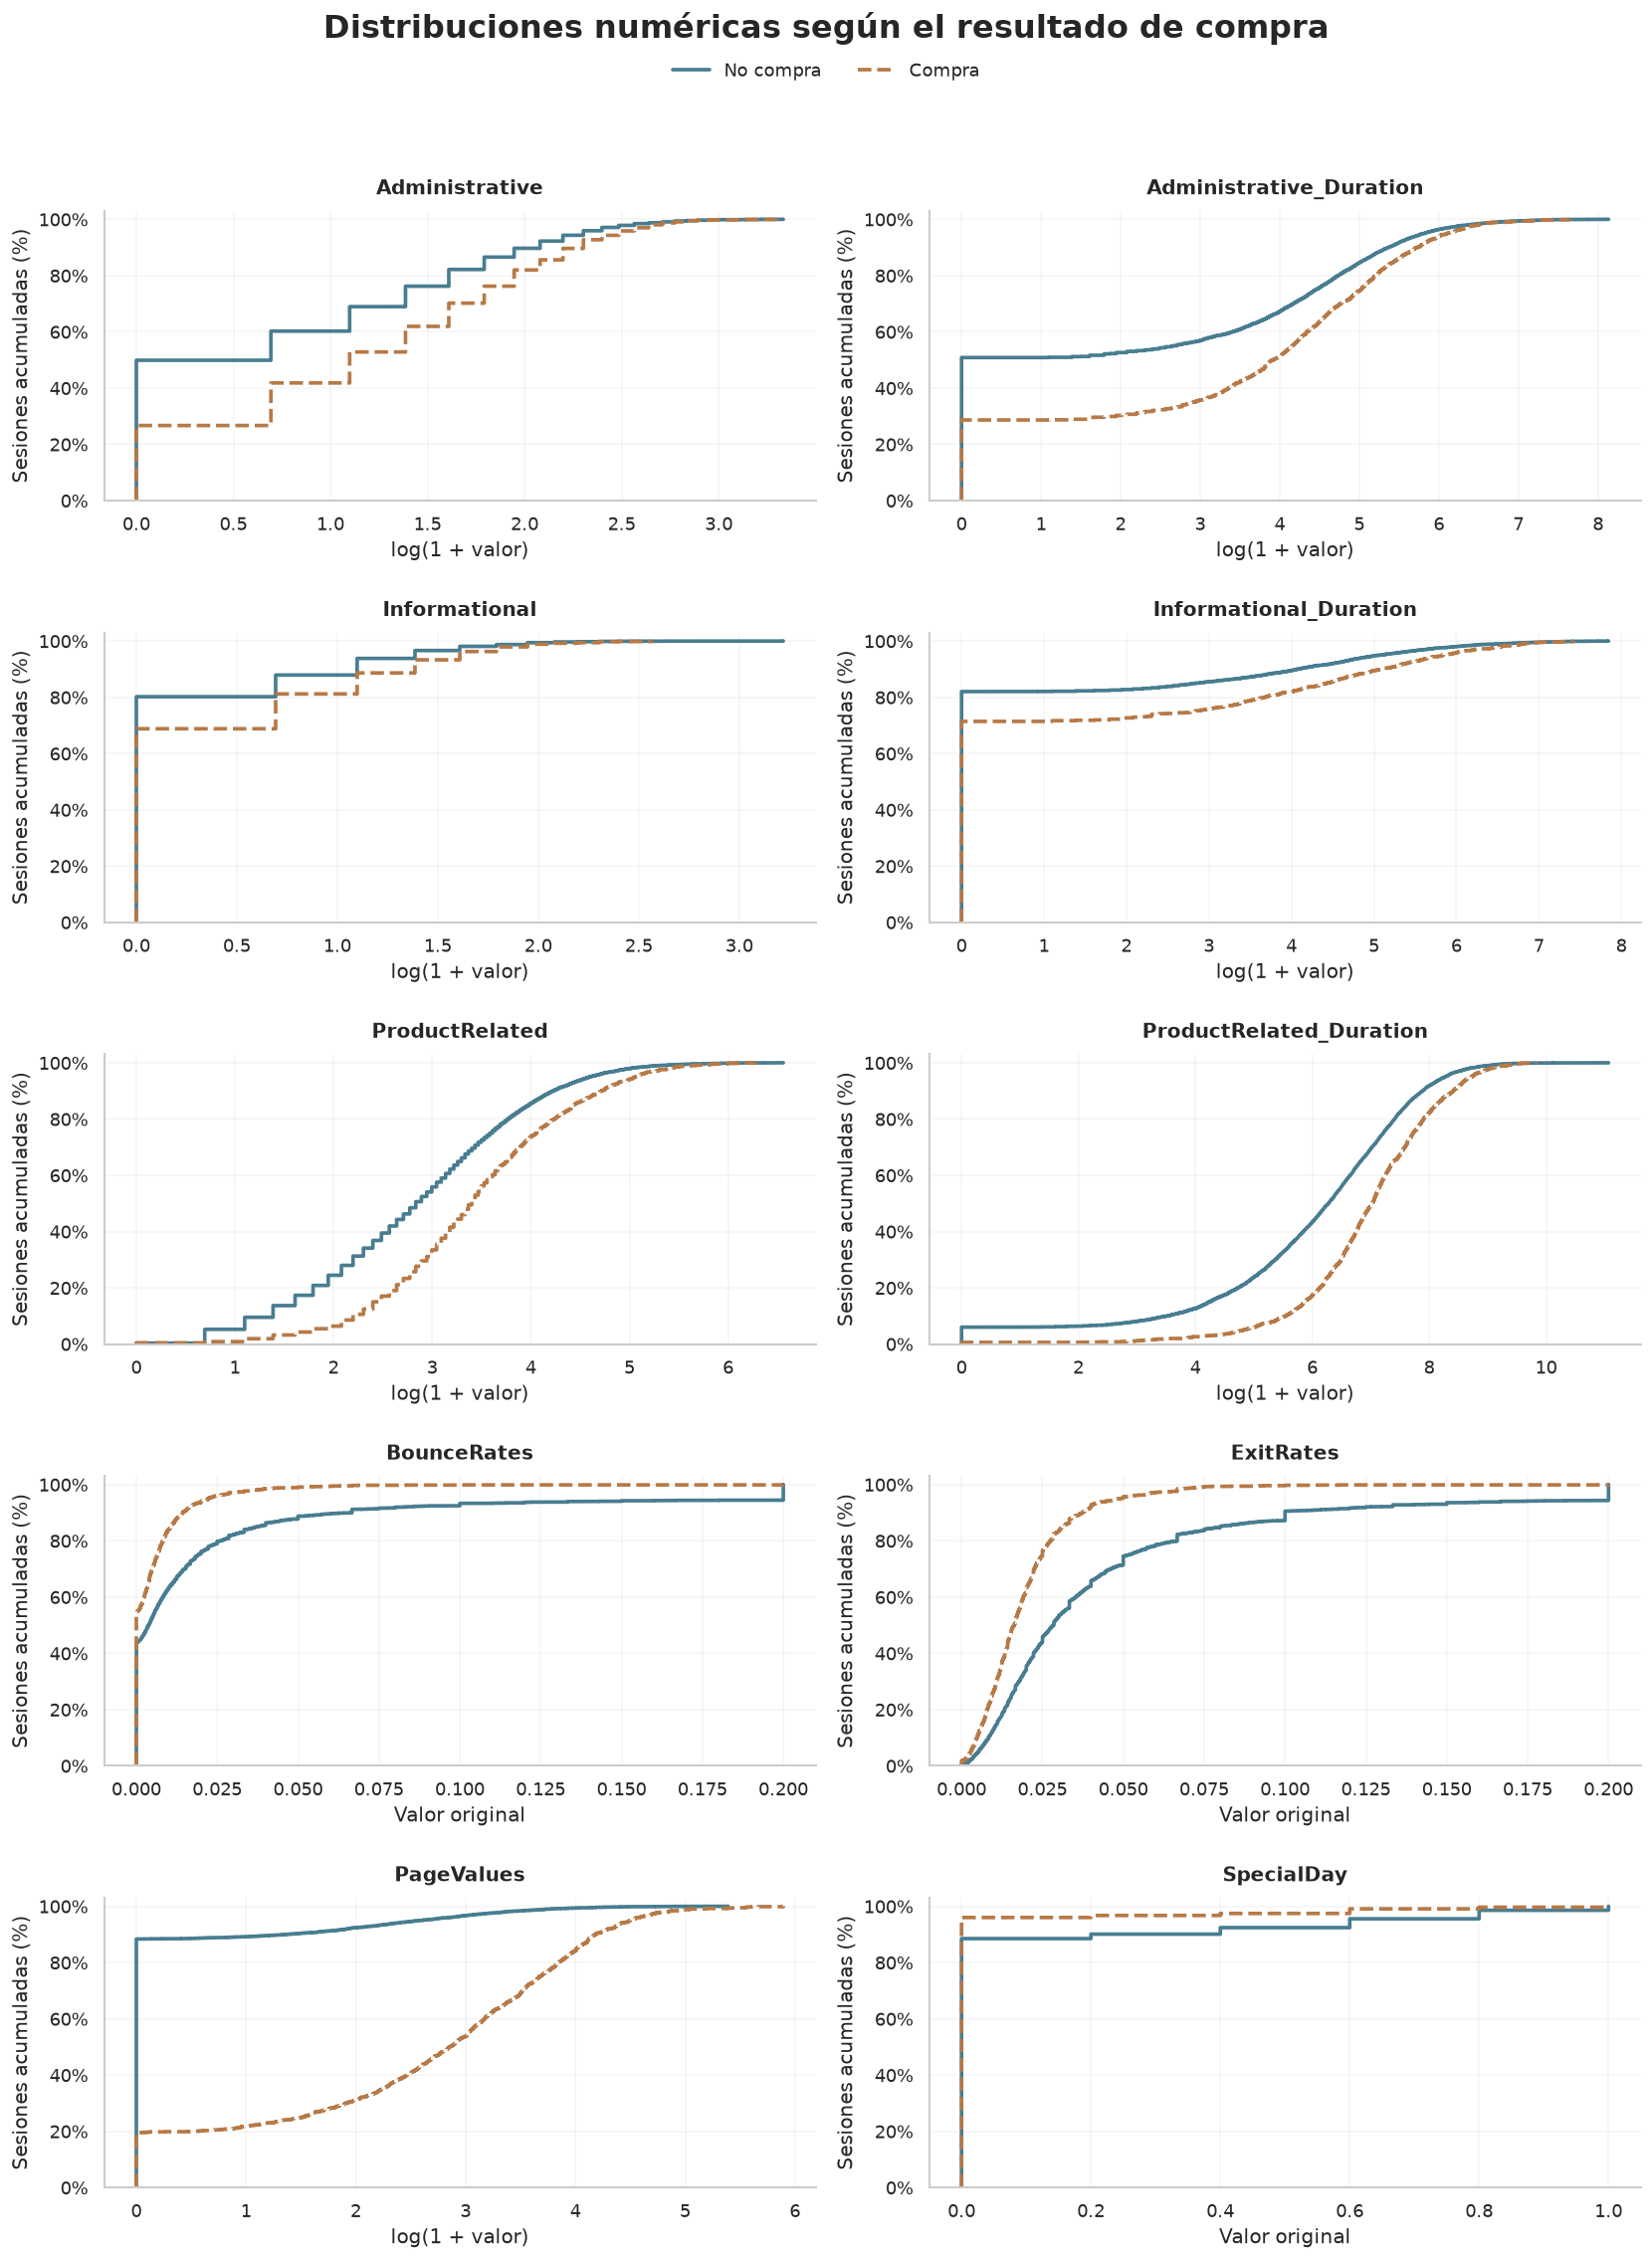

In [105]:
from matplotlib.ticker import PercentFormatter

colores_clases = {
    False: "#487D91",
    True: "#B77946"
}

nombres_clases = {
    False: "No compra",
    True: "Compra"
}

variables_log = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues"
]

fig, axes = plt.subplots(5, 2, figsize=(14, 19))

for ax, variable in zip(axes.flat, variables_numericas):

    for clase in [False, True]:

        valores = df.loc[df["Revenue"] == clase, variable]

        if variable in variables_log:
            valores = np.log1p(valores)

        sns.ecdfplot(
            x=valores,
            ax=ax,
            color=colores_clases[clase],
            linewidth=2.2,
            linestyle="-" if not clase else "--",
            label=nombres_clases[clase]
        )

    ax.set_title(variable, pad=10)
    ax.set_xlabel(
        "log(1 + valor)"
        if variable in variables_log
        else "Valor original"
    )
    ax.set_ylabel("Sesiones acumuladas (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1.03)
    ax.grid(alpha=0.17)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.suptitle(
    "Distribuciones numéricas según el resultado de compra",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=2,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.955], h_pad=2)
plt.show()

**Interpretación**

Las curvas acumuladas confirman que los compradores tienden a registrar una mayor actividad en páginas administrativas y de productos. Esto se aprecia especialmente en `ProductRelated` y `ProductRelated_Duration`, cuyas distribuciones están desplazadas hacia valores superiores.

En cambio, `BounceRates` y `ExitRates` presentan el comportamiento contrario, porque las sesiones con compra tienden a registrar tasas más bajas, especialmente en la tasa de salida.

La separación más grande aparece en `PageValues`. Mientras que la gran mayoría de sesiones sin compra tiene un valor cero, entre los compradores son mucho más frecuentes los valores positivos.

Las diferencias son menos acusadas en `Informational`, `Informational_Duration` y `SpecialDay`, cuyas distribuciones se mantienen relativamente próximas entre ambas clases.

#### 6.3.3. Capacidad de separación individual

Hemos complementado el análisis comparando el **AUC ROC** como puntuación. Este indicador mide la capacidad de ordenar sesiones con compra
por encima de sesiones sin compra a partir de una sola variable.

Un AUC de 0,5 indica ausencia de separación con ese orden. Valores superiores o inferiores reflejan diferencias
en la dirección de la asociación.

,Variable,AUC,"Separación respecto a 0,5"
0,PageValues,0.862,0.362
1,ExitRates,0.301,0.199
2,ProductRelated_Duration,0.669,0.169
3,ProductRelated,0.655,0.155
4,Administrative,0.625,0.125
5,Administrative_Duration,0.618,0.118
6,BounceRates,0.394,0.106
7,Informational,0.558,0.058
8,Informational_Duration,0.555,0.055
9,SpecialDay,0.462,0.038


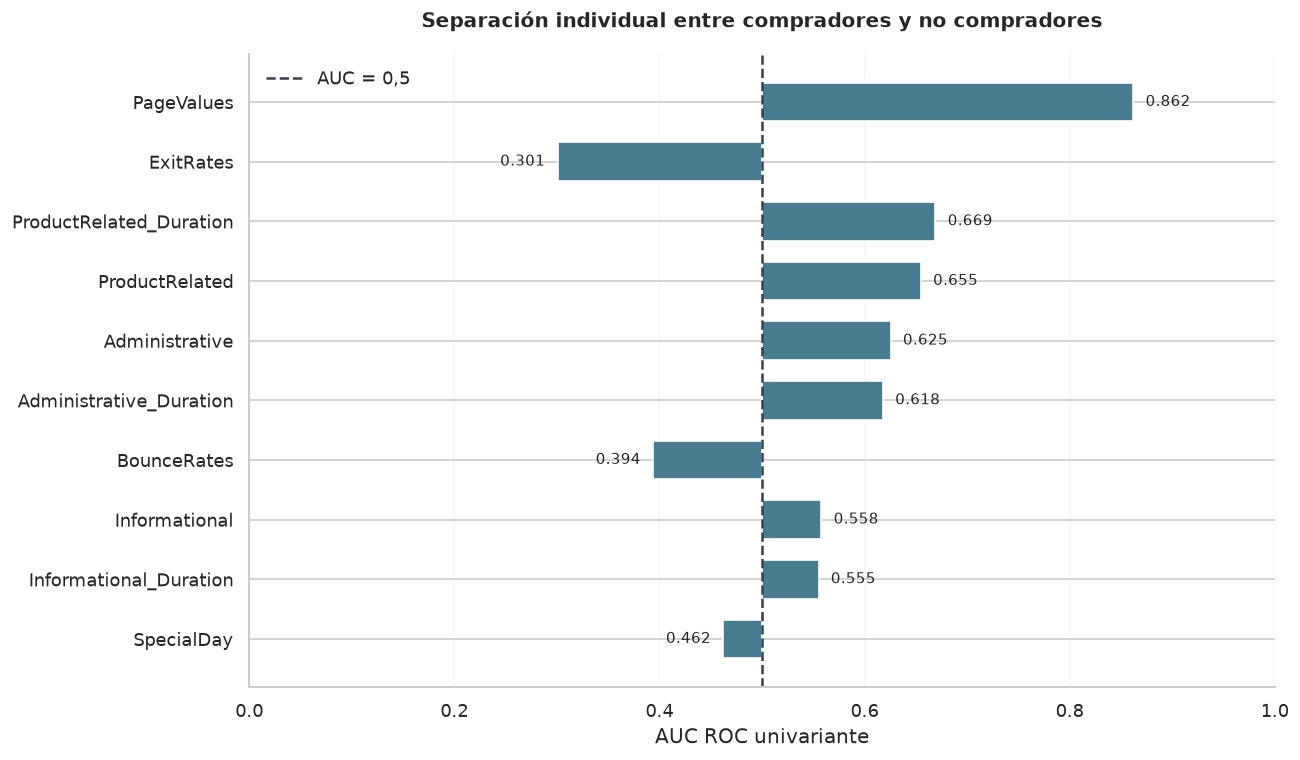

In [106]:
from sklearn.metrics import roc_auc_score

resultados_auc = []

for variable in variables_numericas:

    auc = roc_auc_score(
        df["Revenue"].astype(int),
        df[variable]
    )

    resultados_auc.append({
        "Variable": variable,
        "AUC": auc,
        "Separación respecto a 0,5": abs(auc - 0.5)
    })

tabla_auc = (
    pd.DataFrame(resultados_auc)
    .sort_values("Separación respecto a 0,5", ascending=False)
    .reset_index(drop=True)
)

display(
    tabla_auc.style
    .format({
        "AUC": "{:.3f}",
        "Separación respecto a 0,5": "{:.3f}"
    })
)

# Gráfico centrado en el valor de referencia 0,5
fig, ax = plt.subplots(figsize=(11, 6.5))

posiciones = np.arange(len(tabla_auc))
auc = tabla_auc["AUC"].to_numpy()

ax.barh(
    posiciones,
    auc - 0.5,
    left=0.5,
    height=0.65,
    color="#487D91"
)

ax.axvline(
    0.5,
    color="#374151",
    linewidth=1.5,
    linestyle="--",
    label="AUC = 0,5"
)

ax.set_yticks(
    posiciones,
    labels=tabla_auc["Variable"]
)

ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("AUC ROC univariante")
ax.set_title(
    "Separación individual entre compradores y no compradores",
    pad=16
)

for i, valor in enumerate(auc):
    ax.text(
        valor + (0.012 if valor >= 0.5 else -0.012),
        i,
        f"{valor:.3f}",
        ha="left" if valor >= 0.5 else "right",
        va="center",
        fontsize=9
    )

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.15)

plt.tight_layout()
plt.show()

**Interpretación**

El análisis univariante mediante AUC ROC nos confirma que `PageValues` presenta la mayor capacidad de separación individual, con un **AUC de 0,862**. Le siguen `ExitRates` (0,301), `ProductRelated_Duration` (0,669) y `ProductRelated` (0,655).

El AUC de `ExitRates` es inferior a 0,5 porque su relación con la compra es inversa: los compradores tienden a presentar tasas de salida menores. Si invirtiéramos el sentido de esta variable, obtendríamos un AUC de 0,699, lo que refleja una capacidad de separación considerable.

Por el contrario, `Informational`, `Informational_Duration` y `SpecialDay` presentan valores más próximos a 0,5, indicando una menor capacidad de separación individual mediante este criterio.

### 6.4. Relaciones entre variables numéricas

Además de estudiar su relación con la compra, nos interesa comprobar si las características numéricas están asociadas entre sí.

Algunas variables, como el número de páginas visitadas y su duración, podrían contener información relacionada.

#### 6.4.1. Matriz de correlaciones de Spearman

Hemos calculado la correlación entre las diez características numéricas.

Hemos representado solo la mitad inferior de la matriz para evitar información duplicada. La intensidad del color refleja
la magnitud de la correlación, mientras que el signo distingue las asociaciones positivas de las negativas.

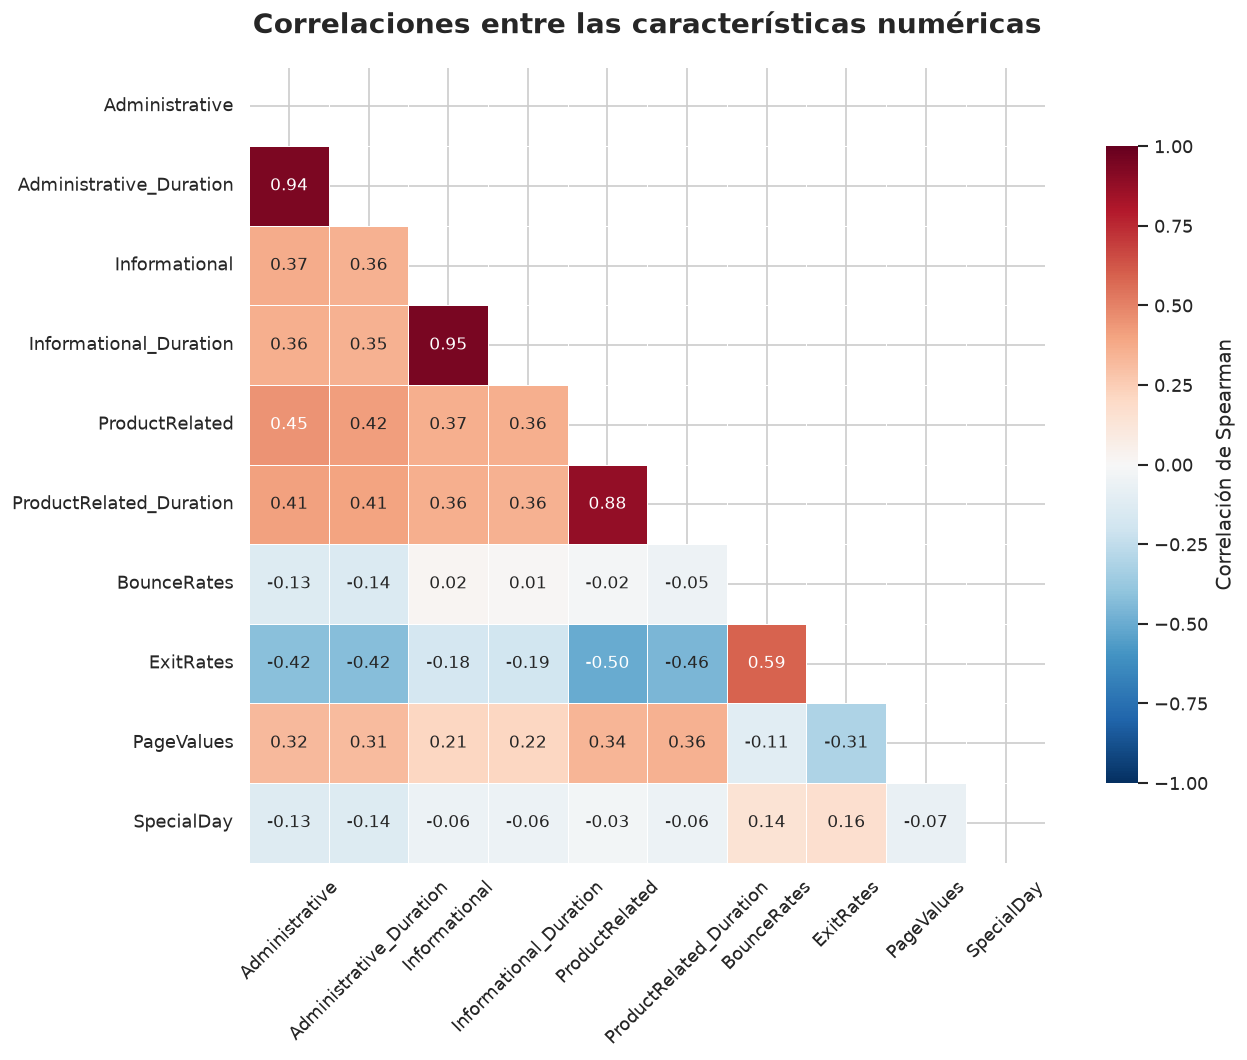

In [107]:
correlaciones = df[variables_numericas].corr(method="spearman")

# Ocultar diagonal y triángulo superior
mascara = np.triu(
    np.ones_like(correlaciones, dtype=bool)
)

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    correlaciones,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 10},
    cbar_kws={
        "label": "Correlación de Spearman",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_title(
    "Correlaciones entre las características numéricas",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

**Interpretación**

- **Recuentos y duraciones:** son las correlaciones más fuertes, especialmente en páginas informativas (**0,949**), administrativas (**0,939**) y de productos (**0,879**). Cuantas más páginas se visitan mayor suele ser el tiempo dedicado a ellas.
- **Tasas de rebote y salida:** `BounceRates` y `ExitRates` presentan una correlación positiva no muy alta (**0,587**), lo que indica que ambas tienden a aumentar conjuntamente.
- **Navegación por productos y tasa de salida:** `ExitRates` se correlaciona negativamente con `ProductRelated` (**−0,505**) y `ProductRelated_Duration` (**−0,459**). Las sesiones con mayor actividad en productos tienden a registrar menores tasas de salida.
- **Actividad entre secciones:** `Administrative` y `ProductRelated` muestran una correlación positiva no muy alta (**0,452**), lo que nos da que pensar que existe cierta asociación entre la navegación administrativa y la de productos.
- **PageValues:** presenta correlaciones positivas moderadas o débiles con las variables de navegación, como `ProductRelated_Duration` (**0,36**) y `ProductRelated` (**0,34**), y negativa con `ExitRates` (**−0,31**).
- **SpecialDay:** mantiene correlaciones débiles con todas las demás variables, sin superar **0,16** en valor absoluto.

#### 6.4.2. Correlaciones de mayor magnitud

Hemos identificado los pares de características que presentan las correlaciones de Spearman más elevadas en valor absoluto.

Hemos ordenado las relaciones por su magnitud, conservando el signopara distinguir asociaciones positivas y negativas.

Estas correlaciones nos pueden ayudar a detectar características que contienen información parcialmente redundante.

In [108]:
from itertools import combinations

pares_correlacion = []

for var1, var2 in combinations(variables_numericas, 2):

    correlacion = correlaciones.loc[var1, var2]

    pares_correlacion.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "Spearman": correlacion,
        "Magnitud": abs(correlacion)
    })

tabla_correlaciones = (
    pd.DataFrame(pares_correlacion)
    .sort_values("Magnitud", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    tabla_correlaciones.style
    .format({
        "Spearman": "{:.3f}",
        "Magnitud": "{:.3f}"
    })
    .background_gradient(
        subset=["Magnitud"],
        cmap="Blues"
    )
    .set_caption("Diez pares de variables con mayor correlación")
)

,Variable 1,Variable 2,Spearman,Magnitud
0,Informational,Informational_Duration,0.949,0.949
1,Administrative,Administrative_Duration,0.939,0.939
2,ProductRelated,ProductRelated_Duration,0.879,0.879
3,BounceRates,ExitRates,0.587,0.587
4,ProductRelated,ExitRates,-0.505,0.505
5,ProductRelated_Duration,ExitRates,-0.459,0.459
6,Administrative,ProductRelated,0.452,0.452
7,Administrative_Duration,ExitRates,-0.423,0.423
8,Administrative_Duration,ProductRelated,0.421,0.421
9,Administrative,ExitRates,-0.420,0.420


**Interpretación**

La tabla confirma que las tres relaciones más fuertes corresponden a los recuentos de páginas y sus respectivas duraciones, todas con correlaciones superiores a 0,87.

Entre las demás relaciones destacan las tasas de rebote y salida (0,587) y la asociación negativa entre páginas de productos visitadas y tasa de salida (−0,505).

#### 6.4.3. Relaciones entre características de navegación

Hemos representado tres pares de variables para examinar visualmente sus relaciones: 
- Recuento y duración de páginas administrativas.
- Recuento y duración de páginas de productos.
- Tasas de rebote y salida.

En los recuentos y duraciones hemos aplicado log(1 + x) solo para poder ver mejor las concentraciones de datos.
Las tasas se mantienen en su escala original.

Hemos decidido utilizar gráficos de densidad hexagonal para evitar la superposición de miles de observaciones, asi se ve por areas pequeñas.

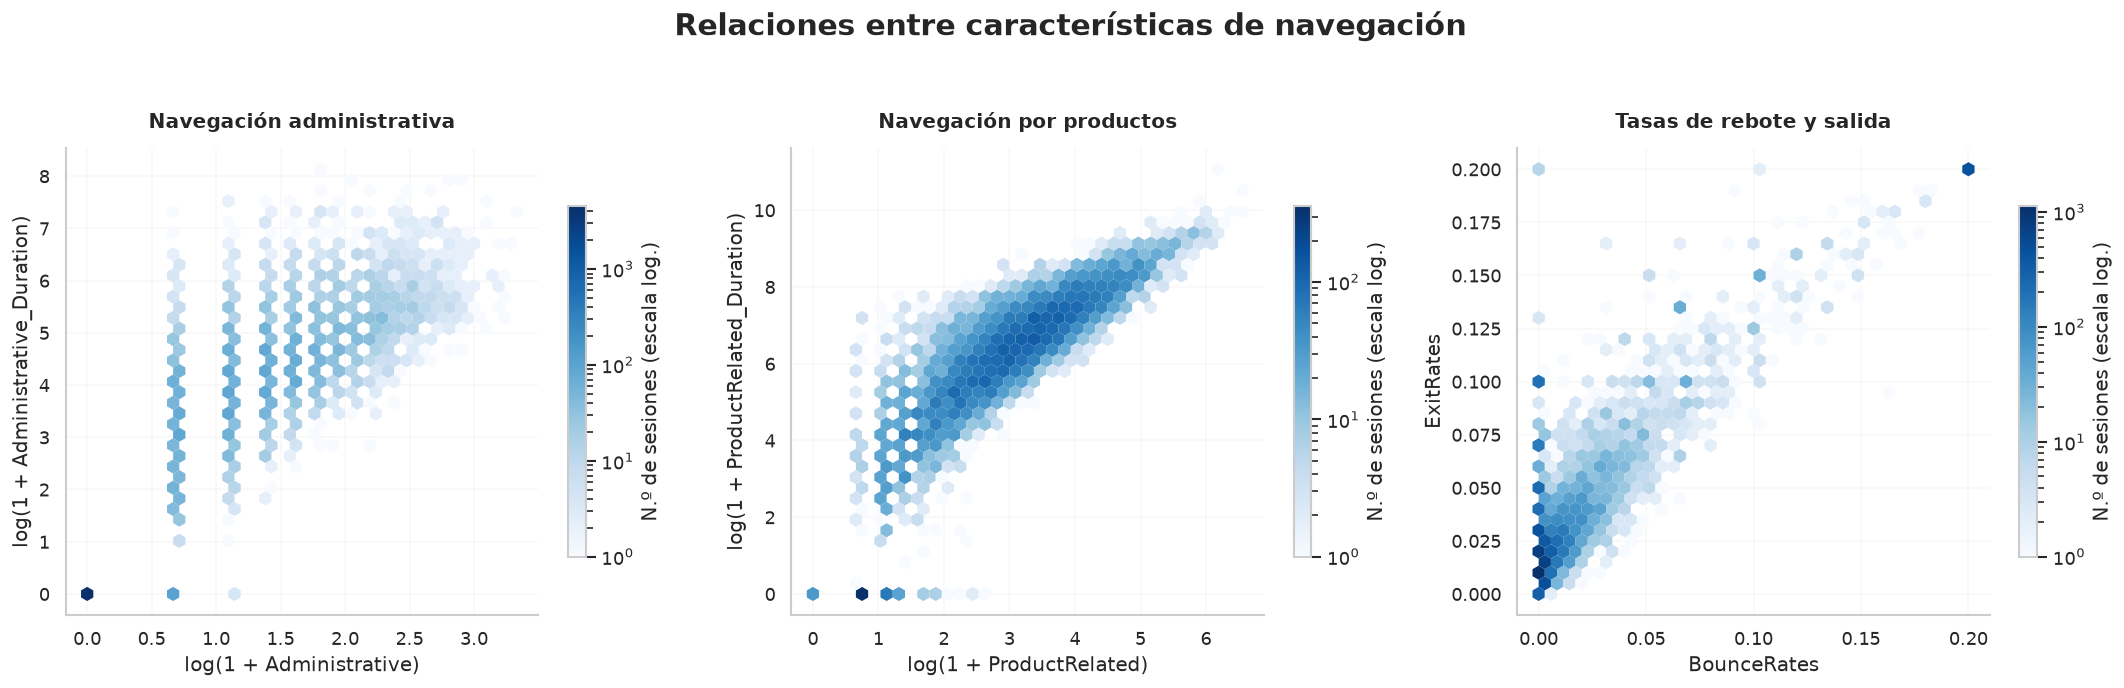

In [109]:
relaciones = [
    (
        "Administrative",
        "Administrative_Duration",
        "Navegación administrativa",
        True
    ),
    (
        "ProductRelated",
        "ProductRelated_Duration",
        "Navegación por productos",
        True
    ),
    (
        "BounceRates",
        "ExitRates",
        "Tasas de rebote y salida",
        False
    )
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (variable_x, variable_y, titulo, usar_log) in zip(
    axes, relaciones
):

    x = df[variable_x]
    y = df[variable_y]

    if usar_log:
        x = np.log1p(x)
        y = np.log1p(y)

    grafico = ax.hexbin(
        x,
        y,
        gridsize=35,
        bins="log",
        mincnt=1,
        cmap="Blues",
        linewidths=0
    )

    ax.set_title(titulo, pad=12)

    ax.set_xlabel(
        f"log(1 + {variable_x})"
        if usar_log else variable_x
    )

    ax.set_ylabel(
        f"log(1 + {variable_y})"
        if usar_log else variable_y
    )

    ax.grid(alpha=0.12)

    barra_color = fig.colorbar(
        grafico,
        ax=ax,
        shrink=0.75
    )
    barra_color.set_label("N.º de sesiones (escala log.)")

fig.suptitle(
    "Relaciones entre características de navegación",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

Los gráficos hexagonales nos permiten ver con mayor claridad las relaciones identificadas mediante Spearman.

En la **navegación administrativa** se aprecia una tendencia positiva entre el número de páginas visitadas y el tiempo dedicado. Las franjas verticales se deben a que el número de páginas es una variable discreta, mientras que la duración admite valores continuos.

La relación se ve incluso más clara en la **navegación por productos**, donde las sesiones se concentran alrededor de una tendencia creciente. Al final cuanto mayor número de páginas visitadas, generalmente mayor duración.

Por último, `BounceRates` y `ExitRates` también muestran una asociación positiva, aunque con mayor dispersión. La mayor concentración de sesiones se encuentra en valores bajos de ambas tasas.

### 6.5. Análisis específico de PageValues

`PageValues` presenta una asociación especialmente marcada con `Revenue`, alcanzando un AUC univariante de 0,862.

Vamos a profundizar en esta relación estudiando las tasas de conversión según sus valores. 
También examinaremos la posible limitación de que si esta característica puede conocerse en el momento en que queremos realizar la predicción.

#### 6.5.1. Conversión según la presencia de PageValues

Hemos comparado la tasa de conversión de las sesiones con `PageValues = 0` con aquellas que presentan un valor positivo.

,Sesiones,Compras,Conversion
Grupo_PageValues,,,
Igual a 0,7577,298,3.93 %
Mayor que 0,2187,1228,56.15 %


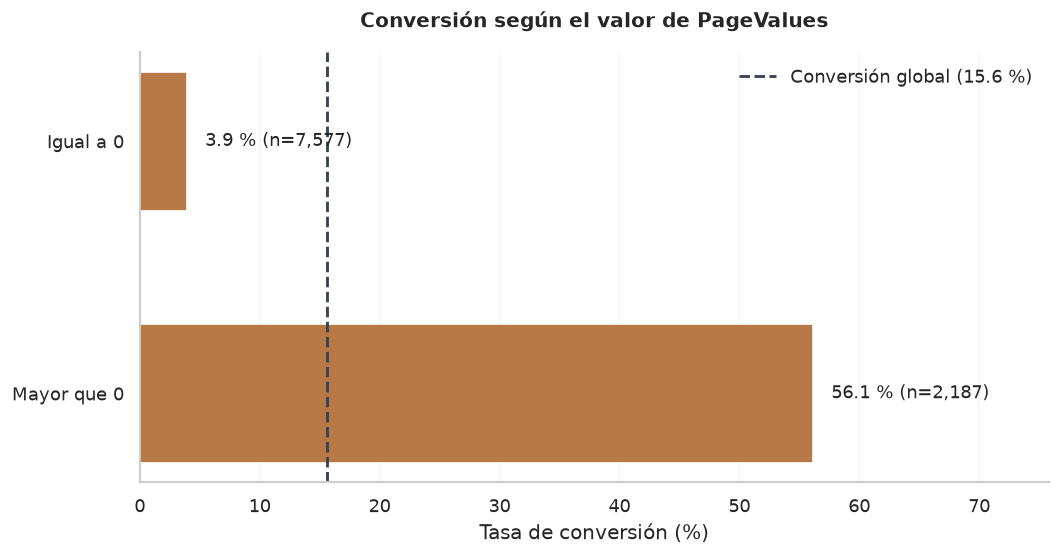

In [110]:
df_page = df.copy()

df_page["Grupo_PageValues"] = np.where(
    df_page["PageValues"] == 0,
    "Igual a 0",
    "Mayor que 0"
)

resumen_page = (
    df_page.groupby("Grupo_PageValues")["Revenue"]
    .agg(Sesiones="size", Compras="sum", Conversion="mean")
    .reindex(["Igual a 0", "Mayor que 0"])
)

resumen_page["Conversion"] *= 100

display(
    resumen_page.style.format({
        "Conversion": "{:.2f} %"
    })
)

fig, ax = plt.subplots(figsize=(9, 4.8))

barras = ax.barh(
    resumen_page.index,
    resumen_page["Conversion"],
    color="#B77946",
    height=0.55
)

ax.axvline(
    tasa_global,
    color="#374151",
    linestyle="--",
    linewidth=1.7,
    label=f"Conversión global ({tasa_global:.1f} %)"
)

limite = max(resumen_page["Conversion"].max(), tasa_global) * 1.35

for barra, (_, fila) in zip(barras, resumen_page.iterrows()):
    ax.text(
        barra.get_width() + limite * 0.02,
        barra.get_y() + barra.get_height() / 2,
        f'{fila["Conversion"]:.1f} % (n={int(fila["Sesiones"]):,})',
        va="center",
        fontsize=11
    )

ax.set_xlim(0, limite)
ax.invert_yaxis()
ax.set_xlabel("Tasa de conversión (%)")
ax.set_title("Conversión según el valor de PageValues", pad=15)
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

Hay bastante diferencia entre ambos grupos. Las sesiones con `PageValues = 0` tienen una tasa de conversión del **3,9 %** y las que tienen valores positivos alcanzan el **56,1 %**, unas 14 veces más.

Esta diferencia nos confirma una fuerte asociación entre `PageValues` y `Revenue`, siendo coherente con el AUC univariante de 0,862. Sin embargo, debemos investigar cómo se obtiene esta característica antes de considerarla adecuada para realizar predicciones reales.

#### 6.5.2. Conversión según la magnitud de PageValues

Hemos analizado solo las sesiones con `PageValues > 0`, dividiéndolas en cinco grupos mediante quintiles.

Cada grupo contiene aproximadamente el mismo número de sesiones para facilitar la comparación de sus tasas de conversión.

Lo que queremos investigar es si existe una tendencia entre el valor de la característica y la frecuencia de compra.

,Quintil,Sesiones,Compras,Conversion,Mediana_PageValues,Grupo
0,"(0.037, 5.69]",438,156,35.62 %,3.11,Q1
1,"(5.69, 11.817]",437,186,42.56 %,8.50,Q2
2,"(11.817, 21.451]",437,245,56.06 %,16.35,Q3
3,"(21.451, 41.516]",437,287,65.68 %,29.66,Q4
4,"(41.516, 361.764]",438,354,80.82 %,60.67,Q5


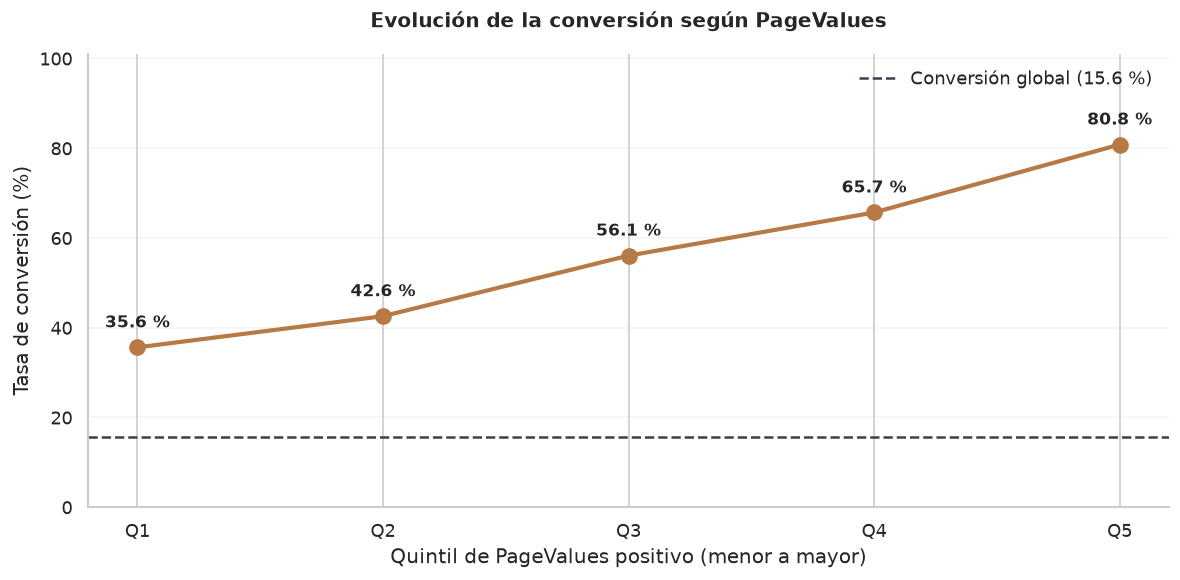

In [111]:
positivas = df.loc[
    df["PageValues"] > 0,
    ["PageValues", "Revenue"]
].copy()

positivas["Quintil"] = pd.qcut(
    positivas["PageValues"],
    q=5,
    duplicates="drop"
)

tabla_quintiles = (
    positivas.groupby("Quintil", observed=True)
    .agg(
        Sesiones=("Revenue", "size"),
        Compras=("Revenue", "sum"),
        Conversion=("Revenue", "mean"),
        Mediana_PageValues=("PageValues", "median")
    )
    .reset_index()
)

tabla_quintiles["Conversion"] *= 100
tabla_quintiles["Grupo"] = [
    f"Q{i+1}" for i in range(len(tabla_quintiles))
]

display(
    tabla_quintiles.style.format({
        "Conversion": "{:.2f} %",
        "Mediana_PageValues": "{:.2f}"
    })
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    tabla_quintiles["Grupo"],
    tabla_quintiles["Conversion"],
    color="#B77946",
    marker="o",
    linewidth=2.5,
    markersize=9
)

ax.axhline(
    tasa_global,
    color="#374151",
    linestyle="--",
    linewidth=1.5,
    label=f"Conversión global ({tasa_global:.1f} %)"
)

for i, fila in tabla_quintiles.iterrows():
    ax.annotate(
        f'{fila["Conversion"]:.1f} %',
        (fila["Grupo"], fila["Conversion"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(
    0,
    max(tabla_quintiles["Conversion"].max(), tasa_global) * 1.25
)
ax.set_xlabel("Quintil de PageValues positivo (menor a mayor)")
ax.set_ylabel("Tasa de conversión (%)")
ax.set_title(
    "Evolución de la conversión según PageValues",
    pad=16
)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

**Interpretación**

Entre las sesiones con `PageValues > 0` la tasa de conversión va aumentando con el valor de la característica, desde el **35,6 % en el primer quintil** hasta el **80,8 % en el quinto**.

La tendencia es claramente creciente en los cinco grupos, lo que nos confirma la asociación positiva entre `PageValues` y la compra.


#### 6.5.3. Origen y disponibilidad de las métricas de Google Analytics

El dataset incluye tres características procedentes de Google Analytics:

- **`BounceRates`:** proporción de sesiones que abandonan una página de entrada sin continuar la interacción, según la definición histórica de Universal Analytics.
- **`ExitRates`:** proporción de visitas a una página que constituyen la última visita de una sesión.
- **`PageValues`:** valor económico medio atribuido a una página a partir de las conversiones realizadas después de visitarla.

Estas métricas pueden calcularse utilizando estadísticas históricas de navegación y conversión. En ese caso, podrían utilizarse para caracterizar nuevas sesiones antes de conocer su resultado. Sin embargo, el dataset no permite comprobar si sus valores se calcularon exclusivamente con información disponible en el momento de la predicción.

El valor histórico de una página en Universal Analytics se calcula mediante:

$$
\text{Page Value} =
\frac{\text{Ingresos atribuidos} + \text{Valor de objetivos}}
{\text{Visitas únicas a la página}}
$$

Aunque Google Analytics 4 ya no ofrece directamente esta métrica es posible construir una aproximación utilizando registros históricos de navegación y eventos de compra, por ejemplo mediante BigQuery.

**Decisiones para el modelado:**

- Hemos mantenido `PageValues` en los experimentos principales, considerando que una métrica equivalente podría estar disponible en una tienda online real.
- Hemos comparado también el rendimiento de los modelos sin esta característica para medir su influencia.
- Como el dataset no permite verificar exactamente cómo se calcularon los valores de cada sesión, hemos documentado esta limitación y el posible riesgo de *data leakage*.

En el notebook 06 desarrollamos una aproximación al cálculo de PageValues utilizando datos históricos de Google Analytics 4.

**Fuentes:** [UCI — Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) · [Google Analytics — Page Value](https://analytics.googleblog.com/2012/07/understanding-and-using-page-value.html) · [Google Analytics 4 — Eventos de compra](https://developers.google.com/analytics/devguides/collection/ga4/set-up-ecommerce)

## 7. Conclusiones del EDA y decisiones para el modelado

El análisis exploratorio nos ha permitido identificar los principales patrones del dataset y tomar decisiones que guiarán los experimentos posteriores.

| Hallazgo | Decisión para el modelado |
|---|---|
| **Calidad de los datos:** no existen valores ausentes y se han detectado 125 registros duplicados. | No hemos aplicado imputación y hemos mantenido la eliminación de duplicados antes de dividir los datos. |
| **Desequilibrio de clases:** únicamente el 15,6 % de las sesiones termina en compra. | Hemos utilizado validación cruzada estratificada y Average Precision como métrica principal. También hemos estudiado técnicas de rebalanceo. |
| **Distribuciones asimétricas:** numerosas variables presentan concentraciones de ceros y valores extremos. | No hemos eliminado observaciones automáticamente. Hemos aplicado el preprocesamiento adecuado dentro de cada Pipeline. |
| **Variables categóricas:** existen categorías muy frecuentes y otras escasamente representadas. | Hemos utilizado One-Hot Encoding y hemos tenido en cuenta las categorías poco frecuentes durante los experimentos. |
| **Navegación y compra:** los compradores tienden a visitar más páginas de productos, dedicarles más tiempo y registrar menores tasas de salida. | Hemos conservado inicialmente todas las variables para comprobar qué información aportan conjuntamente. |
| **Temporalidad y perfil:** noviembre presenta una conversión del 25,4 %, frente al 10,7 % de mayo. Los visitantes nuevos también muestran una mayor tasa de compra que los recurrentes. | Hemos incluido estas características categóricas y evaluado su contribución mediante los modelos. |
| **Correlaciones:** los recuentos de páginas y sus duraciones presentan correlaciones superiores a 0,87. | No hemos eliminado variables únicamente por su correlación. Hemos estudiado su aportación durante el modelado. |
| **PageValues:** presenta la asociación individual más fuerte con la compra (AUC = 0,862), pero su disponibilidad temporal exacta no puede verificarse con el CSV. | Lo hemos mantenido en el análisis principal y hemos comparado el rendimiento con y sin esta característica, documentando sus limitaciones. |